# Análisis de Skim Matrices (TTC y DIST)

- **TTC:** tiempo de viaje (min)
- **DIST:** recorrido de zona a zona (km)
- Análisis de transporte privado (Auto + Heavy Freight + Light Freight) en 4 periodos

| Periodo | Nombre | Horario |
|---|---|---|
| AP | AM Peak | 04:00–08:59 |
| LM | Late Morning | 09:00–11:59 |
| EA | Early Afternoon | 12:00–17:59 |
| PP | PM Peak | 18:00–20:59 |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd


In [2]:
BASE = r"C:\proyectos\red-vial-guadalajara"
SKIMS = os.path.join(BASE, "skim_matrices")
DEMANDA = os.path.join(BASE, "demanda_pf", "Demanda x PF")
SHAPE = os.path.join(SKIMS, "zonas_2105", "zonas_2105.shp")
RESULTADOS = os.path.join(SKIMS, "resultados")
os.makedirs(RESULTADOS, exist_ok=True)

In [3]:
PERIODOS = ["AP", "LM", "EA", "PP"]
N_ZONAS = 2105
SIN_RUTA = 999999
zonas_geo = gpd.read_file(SHAPE)
zonas = sorted(zonas_geo["id_visum"].tolist())

## Bases de datos

In [4]:
# Ejemplo de cómo se ven las skims, en este caso tiempo de zona a zona en am peak
pd.read_csv(os.path.join(SKIMS, "TTC_AP.csv"), nrows=10, usecols=range(11))

,Unnamed: 0,0,1,2,3,4,5,6,7,8,9
0,0,0.000000,0.681254,3.554192,4.310565,5.408254,6.446441,6.978379,7.562477,7.393218,10.639363
1,1,0.122692,0.000000,0.281117,0.820966,2.356178,2.894793,4.386863,3.716520,4.676040,8.047846
2,2,2.823752,0.035647,0.000000,0.856613,2.391825,2.930441,4.422510,3.752167,4.711687,8.083493
3,3,3.889480,0.807214,0.409668,0.000000,0.900598,1.439213,2.667814,2.260940,3.082653,6.328798
4,4,5.060626,2.450640,2.053094,0.987437,0.000000,0.667931,1.199870,1.892022,1.614708,4.860853
5,5,6.532006,3.208057,2.810511,1.744854,0.979469,0.000000,0.049556,0.741708,0.464394,3.710539
6,6,6.888389,4.691922,4.294377,3.040812,1.335852,0.061597,0.000000,0.692152,0.062277,3.308422
7,7,7.569390,3.938738,3.541192,2.475535,2.068519,0.571262,0.803797,0.000000,0.754343,4.504803
8,8,7.343958,4.838892,4.441347,3.375689,1.791421,0.517166,0.058897,0.744088,0.000000,2.613603
9,9,10.598939,8.402472,8.004926,6.751362,5.046402,3.772147,3.313878,4.056525,3.254981,0.000000


In [5]:
# Demanda autos (ejemplo AP)
pd.read_csv(os.path.join(DEMANDA, "matriz_VP_AP.csv")).head(10)

,Hora_inicio,Grupo modal del viaje,Modo,Origen,Destino,Ponderador,Origen_ageb,Destino_ageb,Periodo,Peak Factor,Ponderador_x_PF
0,4,2.- Transporte particular,Transporte Privado,140440011,1404400010100,27,1900,1005,AP,0.367659,9.926788
1,4,2.- Transporte particular,Transporte Privado,140440011,140970005034A,27,1900,5036,AP,0.367659,9.926788
2,4,2.- Transporte particular,Transporte Privado,141011963,999990005,18,7901,10005,AP,0.367659,6.617859
3,4,2.- Transporte particular,Transporte Privado,141011963,1410100010950,144,7901,7053,AP,0.367659,52.942869
4,4,2.- Transporte particular,Transporte Privado,141240029,141240029,9,9901,9901,AP,0.367659,3.308929
5,4,2.- Transporte particular,Transporte Privado,999990004,1412000010369,137,10004,8008,AP,0.367659,50.369257
6,4,2.- Transporte particular,Transporte Privado,999990004,141200758080A,59,10004,8524,AP,0.367659,21.691870
7,4,2.- Transporte particular,Transporte Privado,999990005,140440002012A,7,10005,1015,AP,0.367659,2.573612
8,4,2.- Transporte particular,Transporte Privado,1403900010026,1412000013325,178,1,8173,AP,0.367659,65.443268
9,4,2.- Transporte particular,Transporte Privado,1403900010204,1403900010223,226,11,12,AP,0.367659,83.090891


In [6]:
# Demanda carga pesada y ligera (ejemplo AP)
display(pd.read_csv(os.path.join(DEMANDA, "matriz_HEAVY_FREIGHT_AP.csv")).head(10))
display(pd.read_csv(os.path.join(DEMANDA, "matriz_LIGHT_FREIGHT_AP.csv")).head(10))

,Modo,Hora,Origen,Destino,Origen_ageb,Destino_ageb,Ponderador,hora_inicio,Periodo,Peak Factor,Ponderador_x_PF
0,HEAVY_FREIGHT,06:00-06:59,141200265,EXT_CHAPALA,8005,10005,16.825,6,AP,0.367659,6.185859
1,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,EXT_ZAPOTLANEJO_CUOTA,10004,10004,15.436,6,AP,0.367659,5.675181
2,HEAVY_FREIGHT,06:00-06:59,140392569,EXT_ZAPOTLANEJO_CUOTA,210,10004,11.241,6,AP,0.367659,4.132853
3,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,140395366,10004,412,9.610,6,AP,0.367659,3.533201
4,HEAVY_FREIGHT,06:00-06:59,EXT_COLIMA,EXT_ZAPOTLANEJO_CUOTA,10006,10004,9.268,6,AP,0.367659,3.407462
5,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,140972505,10004,5164,7.357,6,AP,0.367659,2.704866
6,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,140981059,10004,6036,7.357,6,AP,0.367659,2.704866
7,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,EXT_TEPIC,10004,10001,7.357,6,AP,0.367659,2.704866
8,HEAVY_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,EXT_TEPIC,10004,10001,7.357,6,AP,0.367659,2.704866
9,HEAVY_FREIGHT,06:00-06:59,140393707,EXT_ZAPOTLANEJO_CUOTA,260,10004,7.071,6,AP,0.367659,2.599715


,Modo,Hora,Origen,Destino,Origen_ageb,Destino_ageb,Ponderador,hora_inicio,Periodo,Peak Factor,Ponderador_x_PF
0,LIGHT_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,EXT_TEPIC,10004,10001,15.012,6,AP,0.367659,5.519294
1,LIGHT_FREIGHT,06:00-06:59,EXT_COLIMA,EXT_CHAPALA,10006,10005,9.611,6,AP,0.367659,3.533569
2,LIGHT_FREIGHT,06:00-06:59,14120002A,140390308,8901,18,9.536,6,AP,0.367659,3.505994
3,LIGHT_FREIGHT,06:00-06:59,140395366,EXT_TEPIC,412,10001,8.561,6,AP,0.367659,3.147527
4,LIGHT_FREIGHT,06:00-06:59,14039261A,EXT_ZAPOTLANEJO_CUOTA,215,10004,8.481,6,AP,0.367659,3.118114
5,LIGHT_FREIGHT,06:00-06:59,140392605,EXT_COLIMA,214,10006,8.121,6,AP,0.367659,2.985757
6,LIGHT_FREIGHT,06:00-06:59,EXT_ZAPOTLANEJO_CUOTA,140394584,10004,339,7.606,6,AP,0.367659,2.796413
7,LIGHT_FREIGHT,06:00-06:59,140980718,140982428,6023,6131,6.863,6,AP,0.367659,2.523242
8,LIGHT_FREIGHT,06:00-06:59,EXT_TEPIC,141202384,10001,8091,6.224,6,AP,0.367659,2.288308
9,LIGHT_FREIGHT,06:00-06:59,EXT_TEPIC,EXT_TEPIC,10001,10001,6.224,6,AP,0.367659,2.288308


In [7]:
# Zonas de Visum
zonas_geo = gpd.read_file(SHAPE)
print(zonas_geo.shape)
zonas_geo.head(10)

(2105, 20)


,fid,clave_ageb,clave_enti,clave_muni,clave_loca,ageb,nombre_mun,tipo_ageb,poblacion_,area_m2,area_km2,establecim,empleados_,densidad_p,densidad_e,densidad_1,distancia_,consecutiv,id_visum,geometry
0,2207.0,999990001,NaN,0,NaN,TEPIC,Acceso_Vallarta,acceso_carretero,NaN,8.831629e+05,0.883163,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10001,"POLYGON ((2322972.333 977220.634, 2322945.043 ..."
1,2208.0,999990002,NaN,0,NaN,COLOTÁN,Acceso_Colotlan,acceso_carretero,NaN,8.815265e+05,0.881527,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10002,"POLYGON ((2353431.681 1000208.322, 2353404.683..."
2,2209.0,999990003,NaN,0,NaN,SALTILLO,Acceso_Saltillo,acceso_carretero,NaN,8.825597e+05,0.882560,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10003,"POLYGON ((2366603.688 980406.855, 2366576.776 ..."
3,2210.0,999990004,NaN,0,NaN,ZAPO CUOTA,Acceso_Zapotlanejo_Cuota,acceso_carretero,NaN,8.841967e+05,0.884197,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10004,"POLYGON ((2406732.663 970394.079, 2406705.908 ..."
4,2212.0,999990005,NaN,0,NaN,CHAPALA,Acceso_Chapala,acceso_carretero,NaN,8.857317e+05,0.885732,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10005,"POLYGON ((2376622.799 921163.05, 2376596.042 9..."
5,2206.0,999990006,NaN,0,NaN,COLIMA,Acceso_Lopez_Mateos,acceso_carretero,NaN,8.855748e+05,0.885575,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10006,"POLYGON ((2337406.174 932746.039, 2337378.89 9..."
6,2211.0,999990007,NaN,0,NaN,ZAPO LIBRE,Acceso_Zapotlanejo_Libre,acceso_carretero,NaN,8.844008e+05,0.884401,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10007,"POLYGON ((2406070.875 940531.603, 2406044.128 ..."
7,2205.0,999990008,NaN,0,NaN,OCOTLAN,Acceso_Ocotlan,acceso_carretero,NaN,8.857317e+05,0.885732,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10008,"POLYGON ((2397004.785 932025.82, 2396978.029 9..."
8,2204.0,99999000A,NaN,0,NaN,AERO,Tlajomulco de Zúñiga,aeropuerto,NaN,4.770549e+06,4.770549,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10009,"POLYGON ((2363654.887 946588.466, 2361994.858 ..."
9,2.0,1403900010026,14.0,39,1.0,0026,Guadalajara,urbano,1433.0,4.719139e+05,0.471914,67.0,1529.814941,3036.571136,141.975064,3241.724978,5.583186,1.0,1,"POLYGON ((2356822.264 967782.506, 2356822.889 ..."


## Formato largo

In [8]:
def matrix_wide_to_long(df, value_name):
    origin_col = df.columns[0]
    long = df.melt(id_vars=origin_col, var_name="Destination", value_name=value_name)
    long = long.rename(columns={origin_col: "Origin"})
    long["Origin"] = pd.to_numeric(long["Origin"], errors="coerce")
    long["Destination"] = pd.to_numeric(long["Destination"], errors="coerce")
    long[value_name] = pd.to_numeric(long[value_name], errors="coerce")
    return long.dropna(subset=["Origin", "Destination", value_name])

In [9]:
skims_wide = {}
for tipo in ["TTC", "DIST"]:
    for p in PERIODOS:
        skims_wide[f"{tipo}_{p}"] = pd.read_csv(os.path.join(SKIMS, f"{tipo}_{p}.csv"))

for nombre, df in skims_wide.items():
    ids_fila = df.iloc[:, 0].astype(str).tolist()
    print(nombre, df.shape, "filas == columnas:", ids_fila == list(df.columns[1:]))

TTC_AP (2105, 2106) filas == columnas: True
TTC_LM (2105, 2106) filas == columnas: True
TTC_EA (2105, 2106) filas == columnas: True
TTC_PP (2105, 2106) filas == columnas: True
DIST_AP (2105, 2106) filas == columnas: True
DIST_LM (2105, 2106) filas == columnas: True
DIST_EA (2105, 2106) filas == columnas: True
DIST_PP (2105, 2106) filas == columnas: True


se valida que todas sean matrices cuadradas y esté alineada origen-destino, el valor extra se debe a que se agrega uno al leer el csv con read_csv. 

In [10]:
skims_long = {nombre: matrix_wide_to_long(df, nombre.split("_")[0]) for nombre, df in skims_wide.items()}
del skims_wide

for nombre, df in skims_long.items():
    print(nombre, len(df), len(df) == N_ZONAS**2)

TTC_AP 4431025 True
TTC_LM 4431025 True
TTC_EA 4431025 True
TTC_PP 4431025 True
DIST_AP 4431025 True
DIST_LM 4431025 True
DIST_EA 4431025 True
DIST_PP 4431025 True


Esperado: 2105 x 2105 = 4431025 pares por matriz.

## Guardar formato largo
Un CSV por periodo (Origin, Destination, TTC, DIST).

In [11]:
for p in PERIODOS:
    largo = skims_long[f"TTC_{p}"].merge(skims_long[f"DIST_{p}"], on=["Origin", "Destination"])
    ruta = os.path.join(RESULTADOS, f"skims_long_{p}.csv")
    largo.to_csv(ruta, index=False)
    print(p, "guardado en", ruta)
del largo

AP guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados\skims_long_AP.csv
LM guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados\skims_long_LM.csv
EA guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados\skims_long_EA.csv
PP guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados\skims_long_PP.csv


## 5. Clasificación de pares
- **Diagonal:** origen = destino
- **Sin ruta:** valor ≥ 999999
- **Cero fuera de diagonal:** zonas distintas con 0 (su trayectoria y tiempo de traslado es 0, sospechoso)
- **Válidos:** fuera de diagonal, con TTC y DIST > 0

In [12]:
filas = []
for nombre, df in skims_long.items():
    col = nombre.split("_")[0]
    diag = df["Origin"] == df["Destination"]
    sin_ruta = df[col] >= SIN_RUTA
    df["valido"] = ~diag & ~sin_ruta & (df[col] > 0)
    filas.append({
        "Matriz": nombre,
        "Pares": len(df),
        "Diagonal": diag.sum(),
        "Cero fuera diag": ((df[col] == 0) & ~diag).sum(),
        "Sin ruta": sin_ruta.sum(),
        "Válidos": df["valido"].sum(),
        "% válidos": round(df["valido"].mean() * 100, 2),
    })

resumen_pares = pd.DataFrame(filas)
resumen_pares

,Matriz,Pares,Diagonal,Cero fuera diag,Sin ruta,Válidos,% válidos
0,TTC_AP,4431025,2105,18,4208,4424694,99.86
1,TTC_LM,4431025,2105,18,4208,4424694,99.86
2,TTC_EA,4431025,2105,18,4208,4424694,99.86
3,TTC_PP,4431025,2105,18,4208,4424694,99.86
4,DIST_AP,4431025,2105,0,4208,4424712,99.86
5,DIST_LM,4431025,2105,0,4208,4424712,99.86
6,DIST_EA,4431025,2105,0,4208,4424712,99.86
7,DIST_PP,4431025,2105,0,4208,4424712,99.86


## Zonas sin ruta

In [13]:
todas_inalcanzables = set()
todas_aisladas = set()

for nombre, df in skims_long.items():
    col = nombre.split("_")[0]
    sr = df[(df[col] >= SIN_RUTA) & (df["Origin"] != df["Destination"])]

    no_llegadas = sr.groupby("Destination").size()
    no_salidas = sr.groupby("Origin").size()

    inalcanzables = no_llegadas[no_llegadas == N_ZONAS - 1].index.tolist()
    aisladas = no_salidas[no_salidas == N_ZONAS - 1].index.tolist()

    print(nombre, "| inalcanzables:", inalcanzables, "| aisladas:", aisladas)

    todas_inalcanzables.update(inalcanzables)
    todas_aisladas.update(aisladas)

TTC_AP | inalcanzables: [2103] | aisladas: [2103]
TTC_LM | inalcanzables: [2103] | aisladas: [2103]
TTC_EA | inalcanzables: [2103] | aisladas: [2103]
TTC_PP | inalcanzables: [2103] | aisladas: [2103]
DIST_AP | inalcanzables: [2103] | aisladas: [2103]
DIST_LM | inalcanzables: [2103] | aisladas: [2103]
DIST_EA | inalcanzables: [2103] | aisladas: [2103]
DIST_PP | inalcanzables: [2103] | aisladas: [2103]


## 6. Estadísticos (pares válidos)

In [14]:
estadisticos = pd.DataFrame({
    nombre: df.loc[df["valido"], nombre.split("_")[0]].describe(percentiles=[.25, .5, .75, .9, .95, .99])
    for nombre, df in skims_long.items()
}).T.round(2)

estadisticos

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
TTC_AP,4424694.0,34.39,17.79,0.0,21.02,32.52,46.05,58.25,65.43,82.37,167.28
TTC_LM,4424694.0,29.42,14.61,0.0,18.61,28.08,38.82,48.87,55.00,68.80,140.24
TTC_EA,4424694.0,31.63,15.88,0.0,19.82,30.16,41.98,52.82,59.33,74.18,148.08
TTC_PP,4424694.0,32.35,16.39,0.0,20.11,30.75,43.06,54.24,60.92,76.18,173.28
DIST_AP,4424712.0,24.10,13.52,0.1,14.13,22.02,31.71,42.30,49.38,63.97,123.52
DIST_LM,4424712.0,23.91,13.07,0.1,14.18,22.04,31.65,41.71,48.05,61.11,123.58
DIST_EA,4424712.0,23.85,13.15,0.1,14.13,21.93,31.47,41.62,48.20,62.10,126.33
DIST_PP,4424712.0,23.92,13.26,0.1,14.13,21.95,31.55,41.74,48.41,62.79,128.24


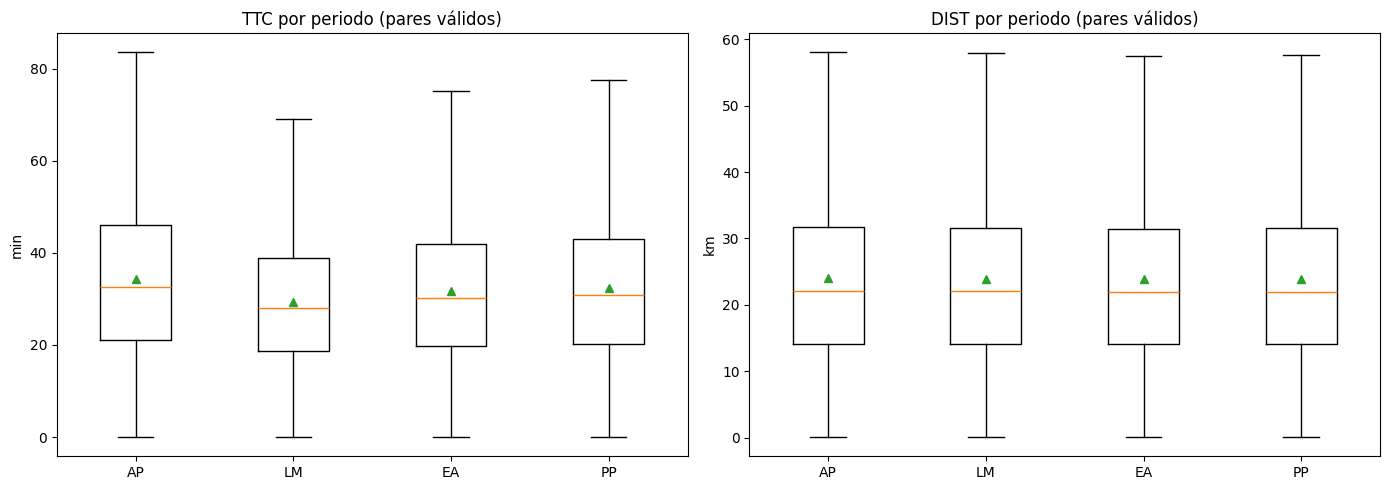

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, tipo, unidad in zip(axes, ["TTC", "DIST"], ["min", "km"]):
    datos = [skims_long[f"{tipo}_{p}"].loc[skims_long[f"{tipo}_{p}"]["valido"], tipo] for p in PERIODOS]
    ax.boxplot(datos, tick_labels=PERIODOS, showfliers=False, showmeans=True)
    ax.set_title(f"{tipo} por periodo (pares válidos)")
    ax.set_ylabel(unidad)
plt.tight_layout()
plt.show()

TTC: las cajas cambian por periodo. AP está más arriba y LM más abajo, es decir cómo  fluctua la congestion del tráfico.

DIST: las cuatro cajas son idénticas porque las rutas no cambian con la hora, sino lo que cambia es la velocidad.

## Pares llamativos

In [16]:
UMBRALES = {"TTC": 75, "DIST": 60}   # umbrales fijos

filas = []
for nombre, df in skims_long.items():
    col = nombre.split("_")[0]
    v = df.loc[df["valido"], col]

    p25 = v.quantile(0.25)
    p75 = v.quantile(0.75)
    limite_tukey = p75 + 1.5 * (p75 - p25)

    filas.append({
        "Matriz": nombre,
        "Umbral fijo": UMBRALES[col],
        "> umbral fijo": (v > UMBRALES[col]).sum(),
        "Límite Tukey": round(limite_tukey, 2),
        "> Tukey": (v > limite_tukey).sum(),
        "% > Tukey": round((v > limite_tukey).mean() * 100, 2),
        "P99": round(v.quantile(0.99), 2),
    })

pares_umbral = pd.DataFrame(filas)
pares_umbral

,Matriz,Umbral fijo,> umbral fijo,Límite Tukey,> Tukey,% > Tukey,P99
0,TTC_AP,75,90944,83.59,38727,0.88,82.37
1,TTC_LM,75,19173,69.12,42489,0.96,68.80
2,TTC_EA,75,40310,75.23,39269,0.89,74.18
3,TTC_PP,75,50669,77.48,37986,0.86,76.18
4,DIST_AP,60,71187,58.06,89515,2.02,63.97
5,DIST_LM,60,50274,57.86,65485,1.48,61.11
6,DIST_EA,60,56292,57.47,75725,1.71,62.10
7,DIST_PP,60,60399,57.68,79463,1.80,62.79


In [17]:
VEL_MIN, VEL_MAX = 5, 120   # límites físicos: más lento que caminar / más rápido que una autopista

filas = []
pares_inconsistentes = {}
for p in PERIODOS:
    m = skims_long[f"TTC_{p}"].merge(skims_long[f"DIST_{p}"], on=["Origin", "Destination"], suffixes=("_ttc", "_dist"))
    m = m[m["valido_ttc"] & m["valido_dist"]].copy()
    m["VEL_kmh"] = m["DIST"] / (m["TTC"] / 60)

    p25 = m["VEL_kmh"].quantile(0.25)
    p75 = m["VEL_kmh"].quantile(0.75)
    tukey_inf = p25 - 1.5 * (p75 - p25)
    tukey_sup = p75 + 1.5 * (p75 - p25)

    raros = m[(m["VEL_kmh"] < VEL_MIN) | (m["VEL_kmh"] > VEL_MAX)]
    pares_inconsistentes[p] = raros[["Origin", "Destination", "TTC", "DIST", "VEL_kmh"]].sort_values("VEL_kmh")

    filas.append({
        "Periodo": p,
        "Vel. mediana (km/h)": round(m["VEL_kmh"].median(), 1),
        "Tukey inferior": round(tukey_inf, 1),
        "Tukey superior": round(tukey_sup, 1),
        "< Tukey inf": (m["VEL_kmh"] < tukey_inf).sum(),
        "> Tukey sup": (m["VEL_kmh"] > tukey_sup).sum(),
        f"< {VEL_MIN} km/h": (m["VEL_kmh"] < VEL_MIN).sum(),
        f"> {VEL_MAX} km/h": (m["VEL_kmh"] > VEL_MAX).sum(),
    })
del m

velocidades = pd.DataFrame(filas)
velocidades

,Periodo,Vel. mediana (km/h),Tukey inferior,Tukey superior,< Tukey inf,> Tukey sup,< 5 km/h,> 120 km/h
0,AP,40.9,27.4,55.5,16929,206593,0,6716
1,LM,46.6,30.6,64.5,15,116210,0,7691
2,EA,43.3,29.1,59.3,120,160274,0,7224
3,PP,42.7,29.3,57.6,4971,168881,0,7090


In [18]:
bins_vel = [0, 5, 20, 40, 60, 80, 110, 120, np.inf]
labels_vel = ["<5 caminar", "5-20 congestión", "20-40 urbano", "40-60 avenida",
              "60-80 Periférico", "80-110 carretera", "110-120 límite autopista", ">120"]

conteos = {}
for p in PERIODOS:
    m = skims_long[f"TTC_{p}"].merge(skims_long[f"DIST_{p}"], on=["Origin", "Destination"], suffixes=("_ttc", "_dist"))
    m = m[m["valido_ttc"] & m["valido_dist"]]
    vel = m["DIST"] / (m["TTC"] / 60)
    conteos[p] = pd.cut(vel, bins=bins_vel, labels=labels_vel, right=False).value_counts(sort=False)
del m, vel

rangos_vel = pd.DataFrame(conteos)
rangos_vel_pct = (rangos_vel / rangos_vel.sum() * 100).round(2)

print("Número de pares por rango de velocidad")
display(rangos_vel)
print("% de pares por rango de velocidad")
display(rangos_vel_pct)

Número de pares por rango de velocidad


,AP,LM,EA,PP
<5 caminar,0,0,0,0
5-20 congestión,109,0,0,170
20-40 urbano,1843489,209390,936296,1126229
40-60 avenida,2471917,3955338,3343487,3185924
60-80 Periférico,85173,230325,118423,88528
80-110 carretera,15932,20044,17650,15206
110-120 límite autopista,1358,1906,1614,1547
>120,6716,7691,7224,7090


% de pares por rango de velocidad


,AP,LM,EA,PP
<5 caminar,0.00,0.00,0.00,0.00
5-20 congestión,0.00,0.00,0.00,0.00
20-40 urbano,41.66,4.73,21.16,25.45
40-60 avenida,55.87,89.39,75.56,72.00
60-80 Periférico,1.92,5.21,2.68,2.00
80-110 carretera,0.36,0.45,0.40,0.34
110-120 límite autopista,0.03,0.04,0.04,0.03
>120,0.15,0.17,0.16,0.16


- La mayoría de los pares tiene una velocidad promedio de 20 a 60 km/h en todos los periodos.
- AP es el periodo más congestionado: 41.7 % de los pares está entre 20 y 40 km/h, contra solo 4.7 % en LM. LM es el más fluido (89.4 % entre 40 y 60 km/h).
- PP (25.5 %) y EA (21.2 %) quedan en medio, con PP un poco más congestionado.
- Prácticamente no hay pares por debajo de 20 km/h (109 en AP y 170 en PP), y ninguno por debajo de 5 km/h.
- Solo 0.4–0.5 % de los pares supera 80 km/h. Los de más de 120 km/h (≈ 7,000 por periodo, 0.15–0.17 %) son físicamente imposibles: tienen tiempos de menos de un segundo en distancias de 0.5 a 1.5 km. Se listan con su zona de Visum en el reporte.

In [20]:
%pip install folium mapclassify

  Using cached folium-0.20.0-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached branca-0.8.2-py3-none-any.whl.metadata (1.7 kB)
Using cached folium-0.20.0-py2.py3-none-any.whl (113 kB)
Using cached branca-0.8.2-py3-none-any.whl (26 kB)
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 13.5 MB/s  0:00:00

   ---------------------------------------- 0/5 [xyzservices]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados


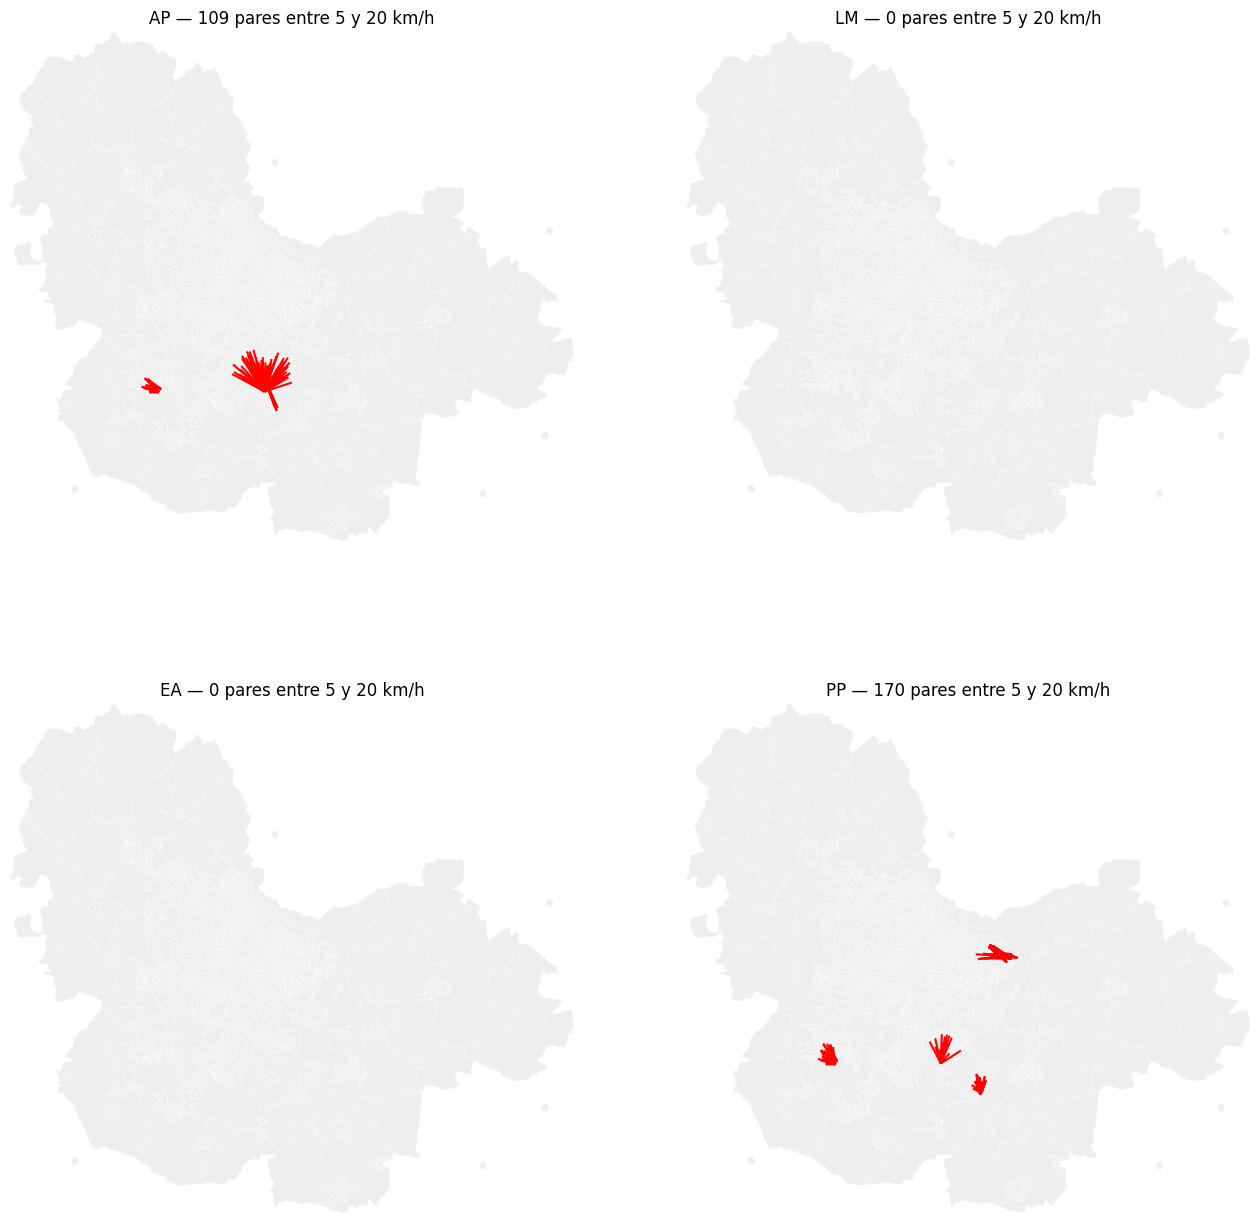

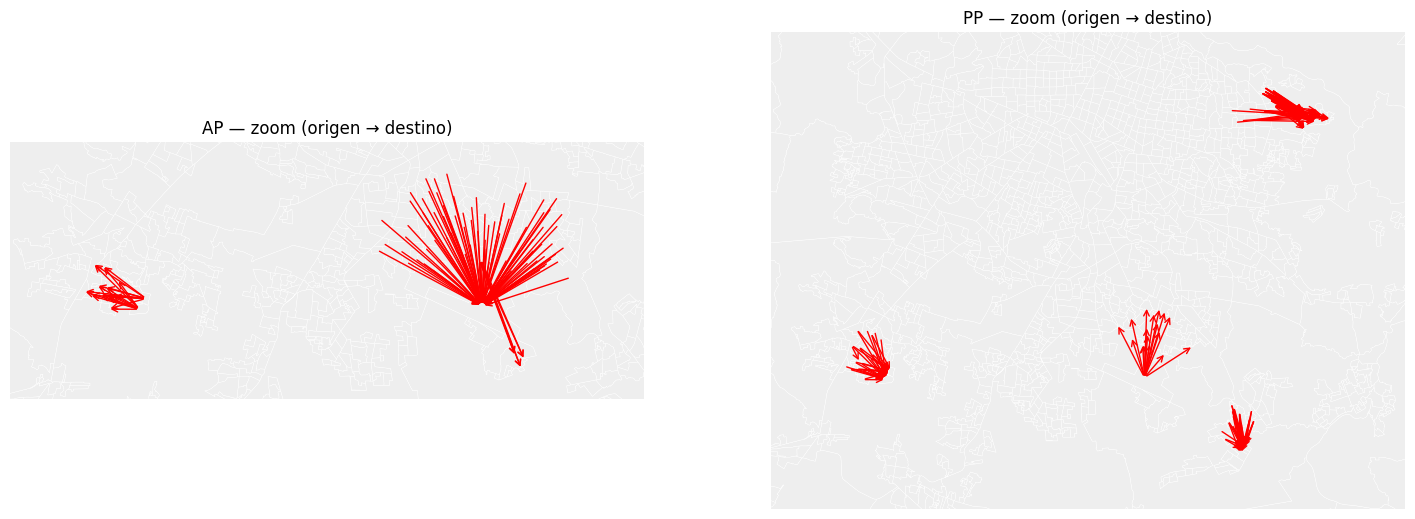

In [25]:
%matplotlib inline

from shapely.geometry import LineString

centros = zonas_geo.set_index("id_visum").geometry.centroid
xmin, ymin, xmax, ymax = zonas_geo[zonas_geo["id_visum"] < 10000].total_bounds
municipio = zonas_geo.set_index("id_visum")["nombre_mun"]

lentos = []
for p in PERIODOS:
    m = skims_long[f"TTC_{p}"].merge(skims_long[f"DIST_{p}"], on=["Origin", "Destination"], suffixes=("_ttc", "_dist"))
    m = m[m["valido_ttc"] & m["valido_dist"]].copy()
    m["VEL_kmh"] = m["DIST"] / (m["TTC"] / 60)
    l = m[(m["VEL_kmh"] >= 5) & (m["VEL_kmh"] < 20)].copy()
    l["Zona_origen"] = [zonas[int(f)] for f in l["Origin"]]
    l["Zona_destino"] = [zonas[int(f)] for f in l["Destination"]]
    l["Periodo"] = p
    lentos.append(l)
del m

lentos = pd.concat(lentos)[["Periodo", "Zona_origen", "Zona_destino", "TTC", "DIST", "VEL_kmh"]].round(2)
lentos.to_csv(os.path.join(RESULTADOS, "pares_5_20_kmh.csv"), index=False)
print("Guardado en", RESULTADOS)

def lineas_lentas(p):
    l = lentos[lentos["Periodo"] == p]
    geometria = [LineString([centros[o], centros[d]]) for o, d in zip(l["Zona_origen"], l["Zona_destino"])]
    return gpd.GeoDataFrame(l, geometry=geometria, crs=zonas_geo.crs)

# Mapas 1-4: toda la ciudad, los 4 periodos
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    lineas = lineas_lentas(p)
    zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
    if len(lineas) > 0:
        lineas.plot(ax=ax, color="red", linewidth=1.5)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{p} — {len(lineas)} pares entre 5 y 20 km/h")
    ax.set_axis_off()
plt.show()

# Mapas 5-6: zoom con flechas origen → destino
con_pares = [p for p in PERIODOS if (lentos["Periodo"] == p).any()]
fig, axes = plt.subplots(1, len(con_pares), figsize=(9 * len(con_pares), 9))
axes = np.atleast_1d(axes)
for ax, p in zip(axes, con_pares):
    l = lentos[lentos["Periodo"] == p]
    zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.3)

    x0, y0, x1, y1 = lineas_lentas(p).total_bounds
    margen_x, margen_y = (x1 - x0) * 0.15, (y1 - y0) * 0.15
    ax.set_xlim(x0 - margen_x, x1 + margen_x)
    ax.set_ylim(y0 - margen_y, y1 + margen_y)

    for o, d in zip(l["Zona_origen"], l["Zona_destino"]):
        ax.annotate("", xy=(centros[d].x, centros[d].y), xytext=(centros[o].x, centros[o].y),
                    arrowprops=dict(arrowstyle="->", color="red", lw=1))

    ax.set_title(f"{p} — zoom (origen → destino)")
    ax.set_axis_off()
plt.show()

### Pares entre 5 y 20 km/h

- Solo AP (109 pares) y PP (170 pares) tienen pares en este rango; LM y EA no tienen ninguno.
- Los pares lentos no están repartidos por la ciudad: se concentran en pocas zonas y forman patrones en estrella desde un mismo punto.
- En AP, la mayoría de los pares lentos tiene como destino la zona 10009, un acceso carretero en Tlajomulco. En PP hay varios focos más pequeños, en Tlajomulco y en Tonalá.
- Estos mapas muestran pares con tiempos de viaje lentos según la skim

In [26]:
import folium
from folium.plugins import PolyLineTextPath

zonas_4326 = zonas_geo.to_crs(4326)

def mapa_interactivo(p):
    lineas = lineas_lentas(p).to_crs(4326)

    mapa = zonas_4326.explore(
        tiles=None,
        color="#eeeeee",
        tooltip=False,
        style_kwds={"color": "white", "weight": 0.5, "fillOpacity": 1},
    )
    lineas.explore(
        m=mapa,
        color="red",
        tooltip=["Zona_origen", "Zona_destino", "TTC", "DIST", "VEL_kmh"],
        style_kwds={"weight": 2},
    )

    for geom in lineas.geometry:
        linea = folium.PolyLine([(y, x) for x, y in geom.coords], weight=0, opacity=0).add_to(mapa)
        PolyLineTextPath(linea, "►", center=True, offset=6,
                         attributes={"fill": "red", "font-size": "16"}).add_to(mapa)

    x0, y0, x1, y1 = lineas.total_bounds
    mapa.fit_bounds([[y0, x0], [y1, x1]])
    return mapa

In [28]:
ruta = os.path.join(RESULTADOS, "mapa_lentos_AP.html")
mapa_interactivo("AP").save(ruta)
print("Guardado en", ruta)
os.startfile(ruta)

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados\mapa_lentos_AP.html


In [29]:
ruta = os.path.join(RESULTADOS, "mapa_lentos_PP.html")
mapa_interactivo("PP").save(ruta)
print("Guardado en", ruta)
os.startfile(ruta)

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados\mapa_lentos_PP.html


AP — top 5 orígenes


,Pares lentos,Municipio
Zona_origen,,
5374,11,Tlajomulco de Zúñiga
5375,10,Tlajomulco de Zúñiga
3063,4,El Salto
3064,4,El Salto
3027,1,El Salto


AP — top 5 destinos


,Pares lentos,Municipio
Zona_destino,,
10009,82,Tlajomulco de Zúñiga
5085,2,Tlajomulco de Zúñiga
5090,2,Tlajomulco de Zúñiga
5092,2,Tlajomulco de Zúñiga
5119,2,Tlajomulco de Zúñiga


PP — top 5 orígenes


,Pares lentos,Municipio
Zona_origen,,
10009,17,Tlajomulco de Zúñiga
7161,11,Tonalá
7070,10,Tonalá
7160,10,Tonalá
7182,8,Tonalá


PP — top 5 destinos


,Pares lentos,Municipio
Zona_destino,,
5374,17,Tlajomulco de Zúñiga
7171,17,Tonalá
5362,14,Tlajomulco de Zúñiga
5363,13,Tlajomulco de Zúñiga
5375,13,Tlajomulco de Zúñiga


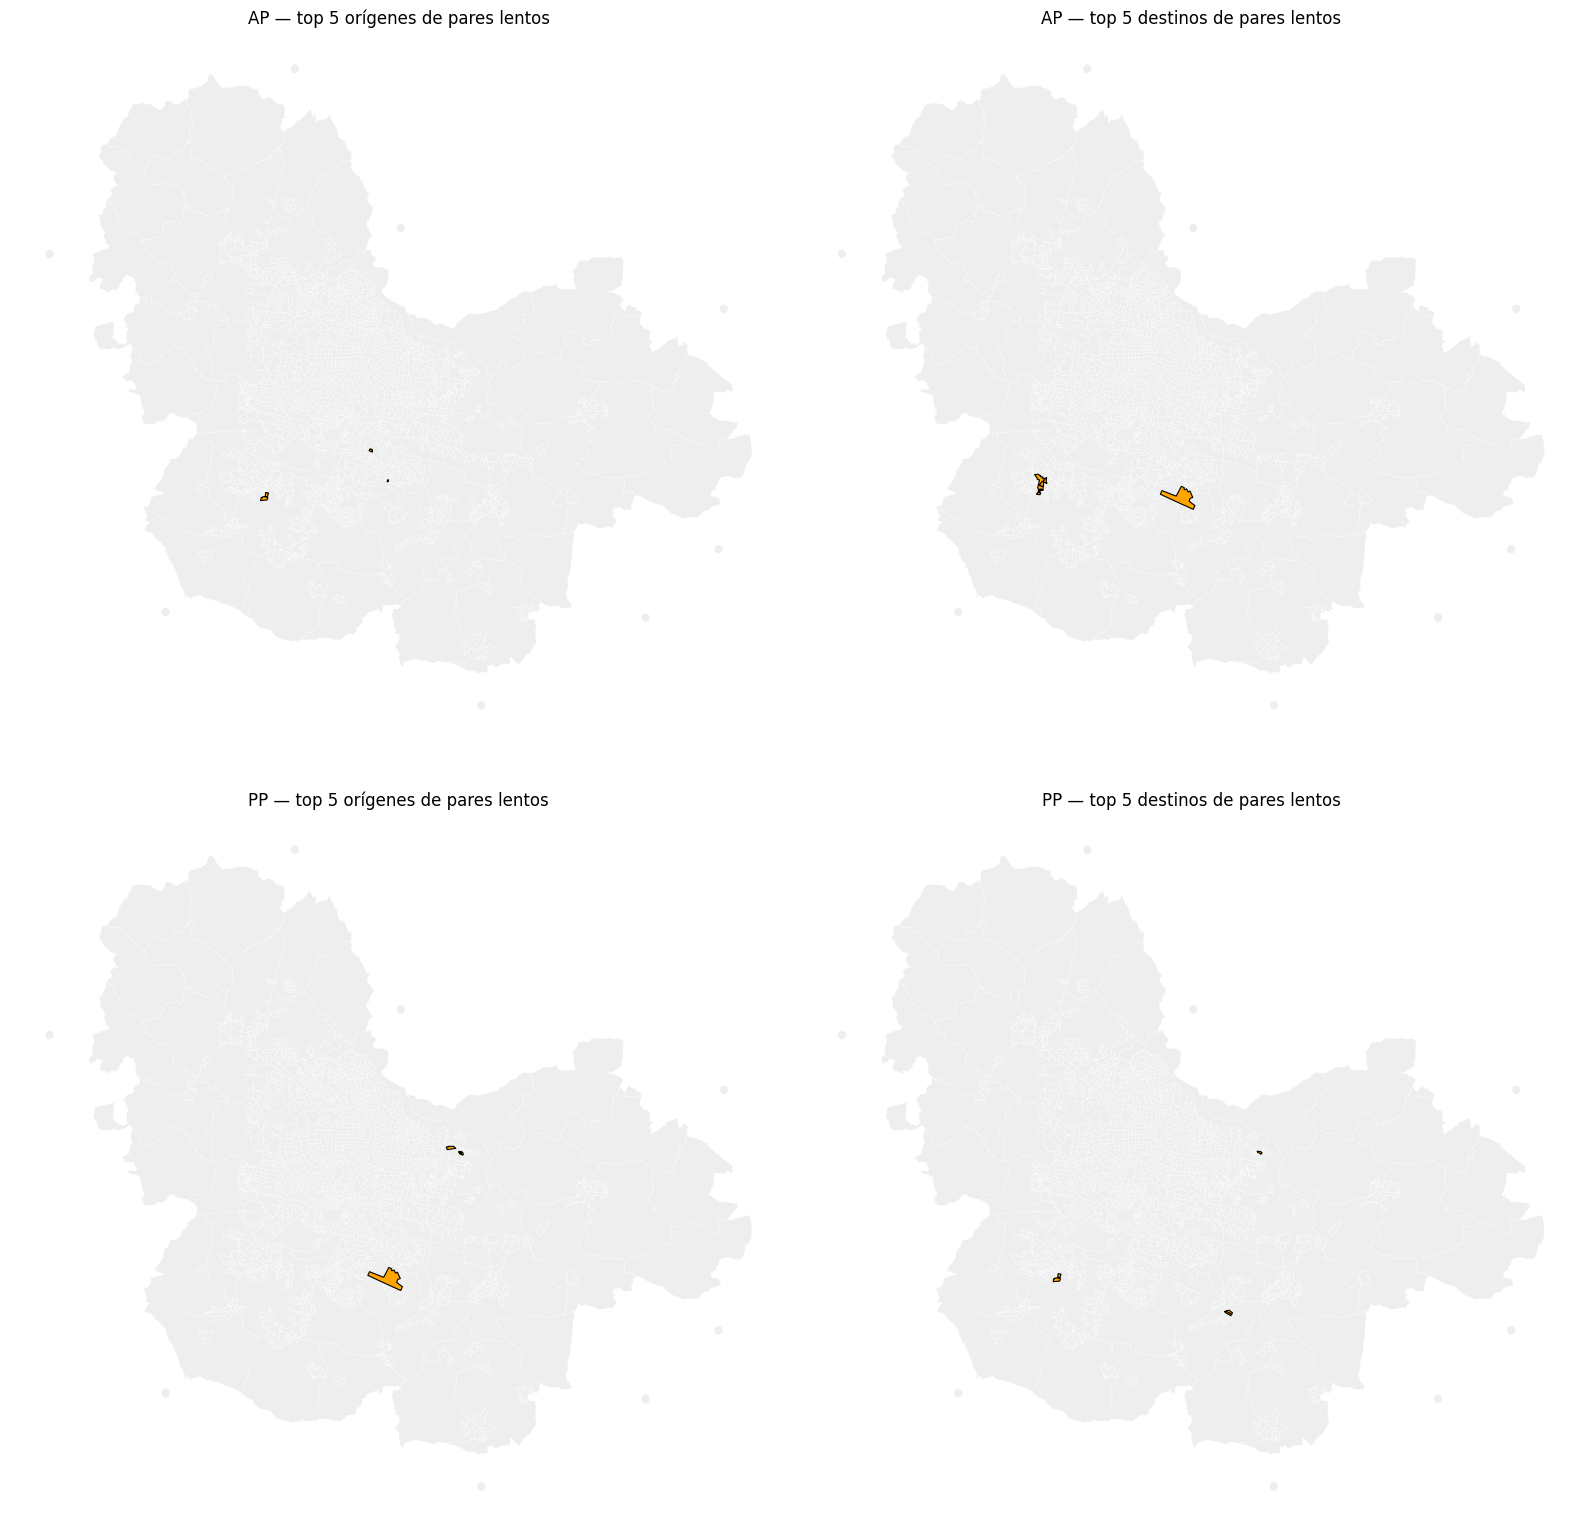

In [30]:
fig, axes = plt.subplots(len(con_pares), 2, figsize=(16, 8 * len(con_pares)))
axes = np.atleast_2d(axes)

for fila, p in enumerate(con_pares):
    l = lentos[lentos["Periodo"] == p]
    for col, (columna, nombre) in enumerate([("Zona_origen", "orígenes"), ("Zona_destino", "destinos")]):
        conteo = l[columna].astype(int).value_counts().head(5)
        zonas_top = zonas_geo[zonas_geo["id_visum"].isin(conteo.index)]

        ax = axes[fila, col]
        zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
        zonas_top.plot(ax=ax, color="orange", edgecolor="black", linewidth=0.8)
        ax.set_title(f"{p} — top 5 {nombre} de pares lentos")
        ax.set_axis_off()

        tabla = conteo.rename("Pares lentos").to_frame()
        tabla["Municipio"] = municipio.reindex(tabla.index).values
        print(f"{p} — top 5 {nombre}")
        display(tabla)

plt.tight_layout()
plt.show()


**AP**
- Destinos: la zona 10009 (acceso carretero) aparece en 82 de los 109 pares lentos.
- Orígenes: zonas del sur, en Tlajomulco (5374, 5375) y El Salto (3063, 3064).
- en AP el tiempo para ir desde zonas del sur hacia el acceso 10009 es muy alto.

**PP**
- Orígenes: la zona 10009 encabeza la lista (17 pares), seguida de zonas de Tonalá (7161, 7070, 7160, 7182).
- Destinos: zonas de Tlajomulco (5374, 5362, 5363, 5375) y la zona 7171 de Tonalá.

**Observaciones**
- Entre las zonas 5374/5375 y el acceso 10009 es lento en los dos picos, en sentidos opuestos

In [31]:
reporte = []
for p in PERIODOS:
    r = pares_inconsistentes[p].copy()
    r["Zona_origen"] = [zonas[int(f)] for f in r["Origin"]]
    r["Zona_destino"] = [zonas[int(f)] for f in r["Destination"]]
    r["TTC_seg"] = r["TTC"] * 60
    r["Periodo"] = p
    reporte.append(r)

reporte = pd.concat(reporte)[["Periodo", "Zona_origen", "Zona_destino", "TTC_seg", "DIST", "VEL_kmh"]]
reporte.to_csv(os.path.join(RESULTADOS, "pares_velocidad_imposible.csv"), index=False)
print("Guardado en", RESULTADOS)

reporte[reporte["Periodo"] == "AP"].nlargest(10, "VEL_kmh").round(2)

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados


,Periodo,Zona_origen,Zona_destino,TTC_seg,DIST,VEL_kmh
3742361,AP,8281,8282,0.48,1.50,11167.68
509670,AP,261,243,0.58,1.57,9840.95
1813264,AP,5225,5227,0.22,0.57,9289.31
1809056,AP,5227,5225,0.23,0.57,9158.14
4365709,AP,9003,9032,0.53,1.11,7509.26
1501580,AP,5081,5079,0.31,0.57,6638.37
3230605,AP,8040,8039,0.75,1.36,6589.08
2238676,AP,6037,6039,0.57,0.99,6271.57
216239,AP,8034,103,0.61,1.01,6035.57
1426103,AP,5906,5043,6.86,9.72,5098.91


In [32]:
for nombre, df in skims_long.items():
    col = nombre.split("_")[0]
    print(nombre)
    display(df.loc[df["valido"]].nlargest(10, col)[["Origin", "Destination", col]])

TTC_AP


,Origin,Destination,TTC
4422525,2025,2100,167.281264
970325,2025,460,155.686042
959800,2025,455,154.938850
949275,2025,450,154.611306
980850,2025,465,153.489995
961905,2025,456,153.185618
976640,2025,463,153.012543
972430,2025,461,152.593361
964010,2025,457,152.482113
968220,2025,459,152.229560


TTC_LM


,Origin,Destination,TTC
4264720,2095,2025,140.238560
4264726,2101,2025,139.862434
4412000,2025,2095,138.478069
1056630,2025,501,129.755640
4264719,2094,2025,128.254357
4390950,2025,2085,127.625847
4264717,2092,2025,127.082856
4393055,2025,2086,127.076837
4409895,2025,2094,127.029895
4263126,501,2025,126.361799


TTC_EA


...

,Origin,Destination,DIST
4264726,2101,2025,123.580802
4416286,2101,2097,121.216267
4266831,2101,2026,119.072378
4420420,2025,2099,117.789633
4271041,2101,2028,117.132554
4273146,2101,2029,115.822553
4414181,2101,2096,115.810373
4420492,2097,2099,115.396319
4420421,2026,2099,113.252430
4419407,1012,2099,112.618295


DIST_EA


,Origin,Destination,DIST
4264726,2101,2025,126.332060
4416286,2101,2097,123.967700
4266831,2101,2026,121.823812
2132359,2099,1012,119.188932
2132362,2102,1012,119.106076
4273146,2101,2029,118.573811
4420420,2025,2099,117.698254
4271041,2101,2028,117.103434
1399819,2099,664,115.832315
4414181,2101,2096,115.781253


DIST_PP


,Origin,Destination,DIST
4264726,2101,2025,128.242283
4416286,2101,2097,123.857906
4418391,2101,2098,123.752307
4266831,2101,2026,121.714018
4273146,2101,2029,120.484034
2132359,2099,1012,119.188932
2132362,2102,1012,119.106076
4292091,2101,2038,118.491467
4420420,2025,2099,117.828267
4271041,2101,2028,117.158251


## Histogramas por pares
Bins de 5 min y 5 km.

In [33]:
config = {
    "TTC":  (list(range(0, 185, 5)) + [np.inf], [f"{i}-{i+5}" for i in range(0, 180, 5)] + ["180+"], "min"),
    "DIST": (list(range(0, 105, 5)) + [np.inf], [f"{i}-{i+5}" for i in range(0, 100, 5)] + ["100+"], "km"),
}

def graficar(tablas, columna, etiqueta_y, titulo):
    for p in PERIODOS:
        for tipo in ["TTC", "DIST"]:
            t = tablas[f"{tipo}_{p}"]
            fig, ax = plt.subplots(figsize=(14, 4))
            barras = ax.bar(t.index.astype(str), t[columna])
            ax.bar_label(barras, fmt="%.1f", fontsize=7)
            ax.set_title(f"{tipo} {p} — {titulo}")
            ax.set_xlabel(f"Intervalo ({config[tipo][2]})")
            ax.set_ylabel(etiqueta_y)
            ax.tick_params(axis="x", rotation=90, labelsize=8)
            plt.tight_layout()
            plt.show()

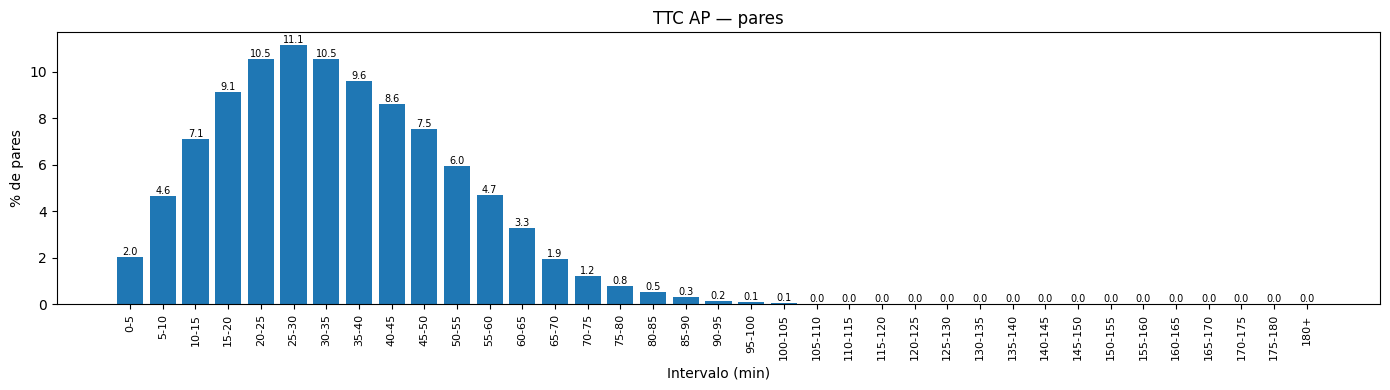

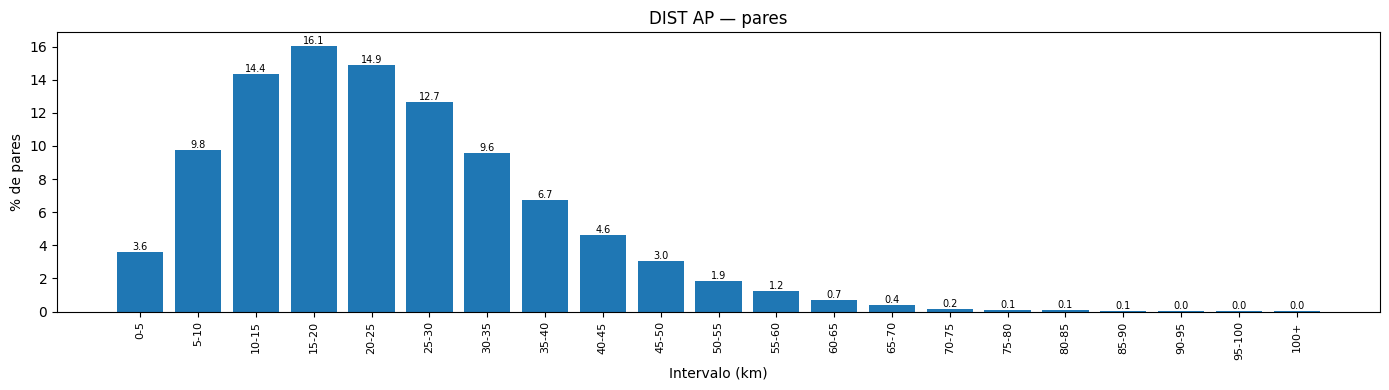

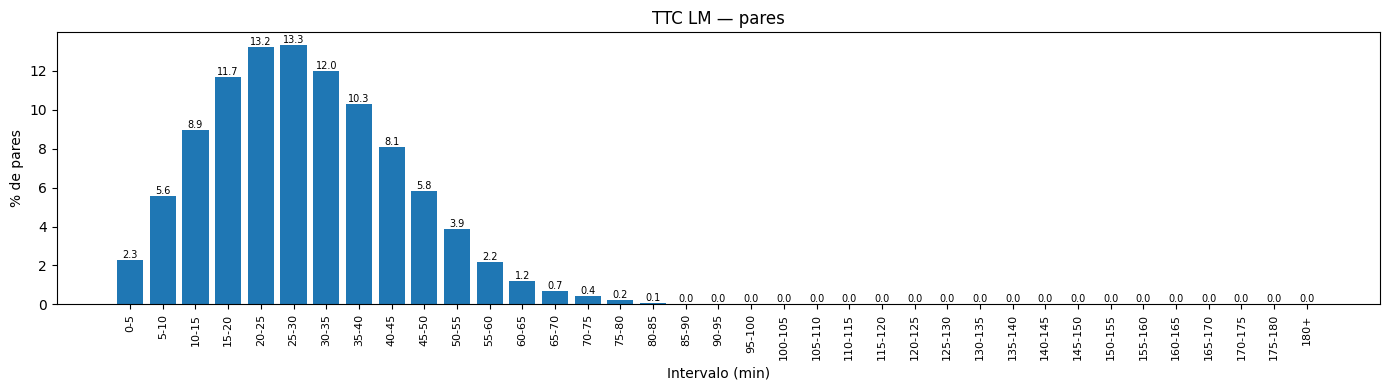

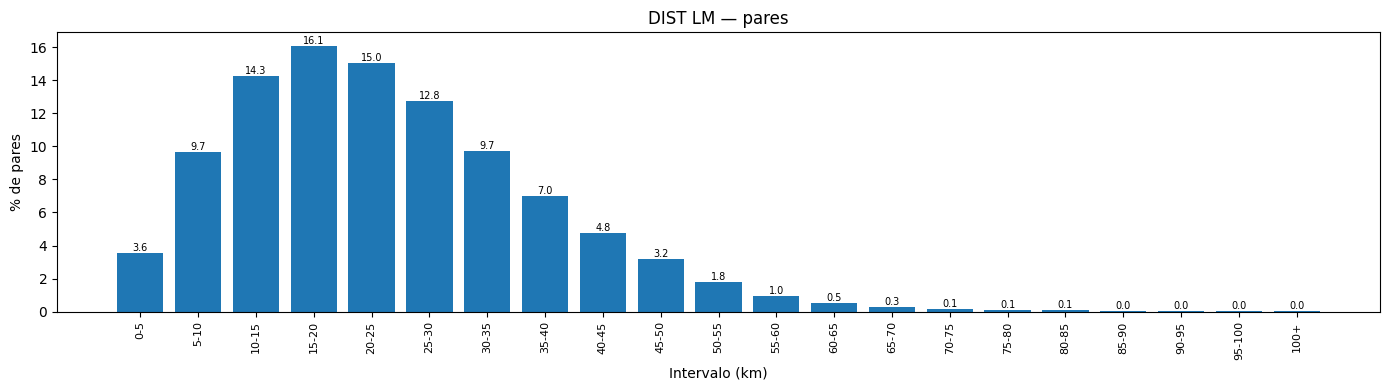

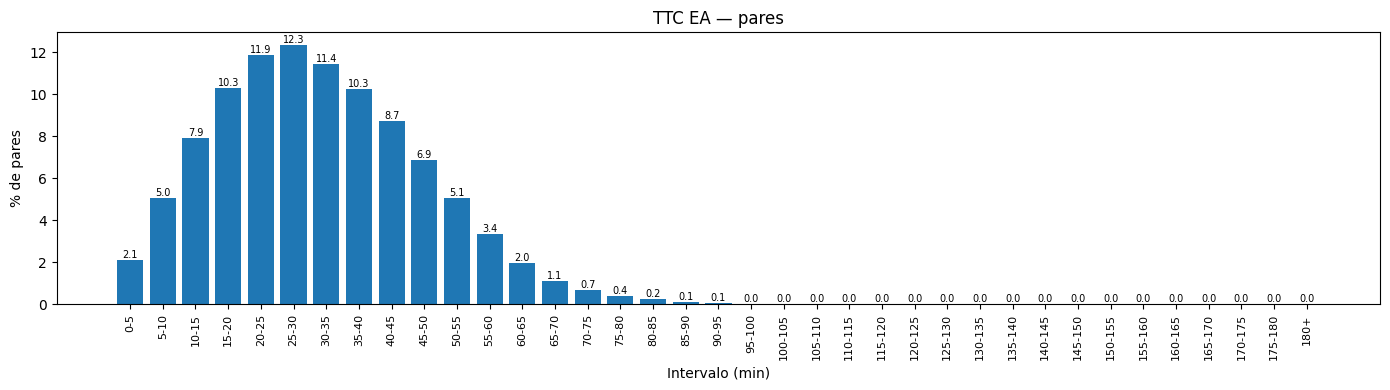

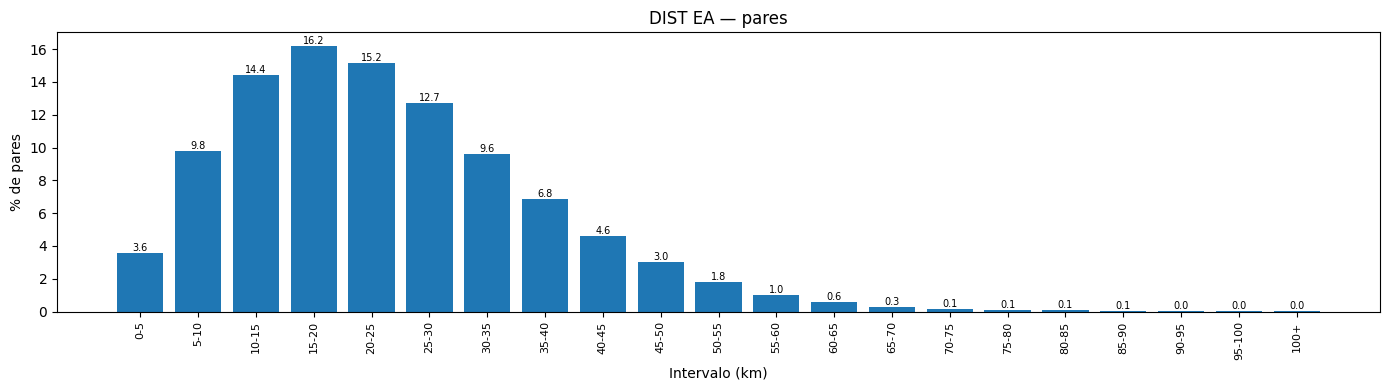

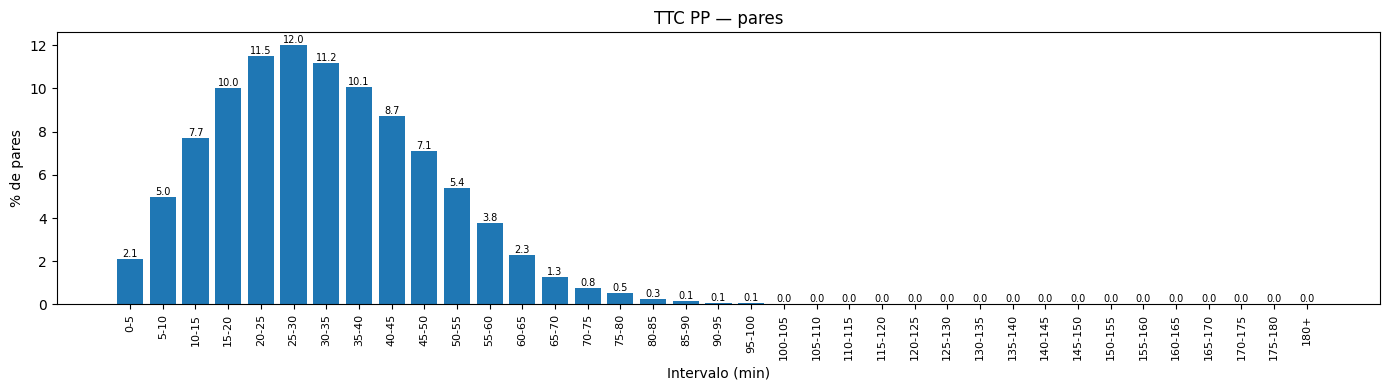

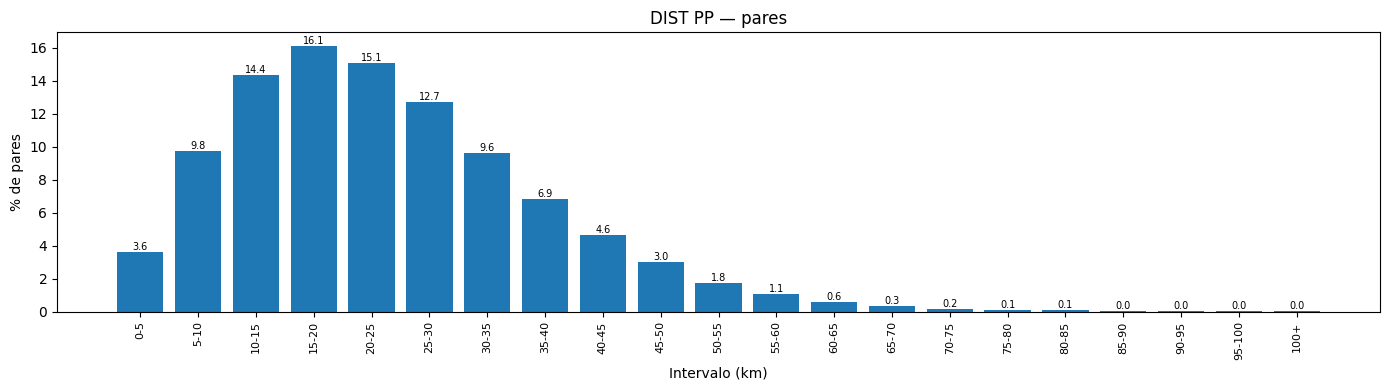

In [34]:
hist_pares = {}
for p in PERIODOS:
    for tipo in ["TTC", "DIST"]:
        bins, labels, _ = config[tipo]
        df = skims_long[f"{tipo}_{p}"]
        intervalos = pd.cut(df.loc[df["valido"], tipo], bins=bins, labels=labels, right=False)
        t = intervalos.value_counts(sort=False).rename("Pares").to_frame()
        t["% pares"] = (t["Pares"] / t["Pares"].sum() * 100).round(2)
        hist_pares[f"{tipo}_{p}"] = t

graficar(hist_pares, "% pares", "% de pares", "pares")


**Tiempo (TTC)**
- En los 4 periodos, el intervalo más frecuente es de 25 a 30 min (11.1 % en AP, 13.3 % en LM, 12.3 % en EA y 12.0 % en PP).
- AP tiene la distribución más extendida hacia la derecha: solo 44.4 % de los pares tarda menos de 30 min, contra 55.0 % en LM, 49.5 % en EA y 48.3 % en PP.
- Los pares de más de 60 min son 8.4 % en AP, 5.5 % en PP, 4.6 % en EA y 2.6 % en LM. El orden coincide con la congestión esperada: AP es el periodo más lento y LM el más rápido.
- Prácticamente no hay pares de más de 100 min en ningún periodo.

**Distancia (DIST)**
- Las 4 distribuciones son prácticamente idénticas: el intervalo más frecuente es de 15 a 20 km (≈ 16 %) y alrededor de 77 % de los pares está entre 5 y 35 km.
- Solo ≈ 3.6 % de los pares está a menos de 5 km y ≈ 4–5 % a más de 50 km.
- Que la distancia no cambie entre periodos y el tiempo sí indica que las rutas son similares en todo el día y lo que cambia es la velocidad por la congestión.


## Histogramas por viajes


In [35]:
MODOS = ["VP", "HEAVY_FREIGHT", "LIGHT_FREIGHT"]

def cargar_demanda(path):
    d = pd.read_csv(path)
    d = d.groupby(["Origen_ageb", "Destino_ageb"], as_index=False)["Ponderador_x_PF"].sum()
    d.columns = ["Origin_zona", "Destination_zona", "Trips"]
    return d

demanda_modo = {}
filas = []
for p in PERIODOS:
    for modo in MODOS:
        d = cargar_demanda(os.path.join(DEMANDA, f"matriz_{modo}_{p}.csv"))
        demanda_modo[(p, modo)] = d
        filas.append({"Periodo": p, "Modo": modo, "Pares": len(d), "Viajes": round(d["Trips"].sum(), 1)})

viajes_modo = pd.DataFrame(filas)
viajes_modo

,Periodo,Modo,Pares,Viajes
0,AP,VP,8733,364851.0
1,AP,HEAVY_FREIGHT,261,555.1
2,AP,LIGHT_FREIGHT,329,715.3
3,LM,VP,4395,173472.0
4,LM,HEAVY_FREIGHT,577,1365.2
5,LM,LIGHT_FREIGHT,744,1671.5
6,EA,VP,12573,297556.0
7,EA,HEAVY_FREIGHT,887,1332.7
8,EA,LIGHT_FREIGHT,1147,1551.9
9,PP,VP,5922,298480.0


In [39]:
totales = viajes_modo.pivot(index="Periodo", columns="Modo", values="Viajes")
totales = totales.loc[PERIODOS, MODOS]
totales["Total"] = totales.sum(axis=1)
totales.loc["Total"] = totales.sum()
totales.round(1)

Modo,VP,HEAVY_FREIGHT,LIGHT_FREIGHT,Total
Periodo,,,,
AP,364851.0,555.1,715.3,366121.4
LM,173472.0,1365.2,1671.5,176508.7
EA,297556.0,1332.7,1551.9,300440.6
PP,298480.0,717.3,829.9,300027.2
Total,1134359.0,3970.3,4768.6,1143097.9


Total de viajes en la base, no de todo el día porque faltan dos horarios

In [36]:
HAY_ZONAS = len(zonas) == N_ZONAS
print("Zonas:", len(zonas), "| coincide con skims:", HAY_ZONAS)
posicion = {z: i for i, z in enumerate(zonas)}

Zonas: 2105 | coincide con skims: True


### Cruce demanda × skims


In [37]:
if HAY_ZONAS:
    cruces = {}
    filas = []
    for p in PERIODOS:
        d = pd.concat([demanda_modo[(p, m)] for m in MODOS])
        d = d.groupby(["Origin_zona", "Destination_zona"], as_index=False)["Trips"].sum()
        d["Origin"] = d["Origin_zona"].map(posicion)
        d["Destination"] = d["Destination_zona"].map(posicion)
        sin_mapeo = d["Origin"].isna() | d["Destination"].isna()
        d = d[~sin_mapeo]

        c = d.merge(skims_long[f"TTC_{p}"][["Origin", "Destination", "TTC"]], on=["Origin", "Destination"])
        c = c.merge(skims_long[f"DIST_{p}"][["Origin", "Destination", "DIST"]], on=["Origin", "Destination"])
        intra = c["Origin"] == c["Destination"]
        sin_ruta = c["TTC"] >= SIN_RUTA
        ok = ~intra & ~sin_ruta
        cruces[p] = c[ok]

        w = c.loc[ok, "Trips"]
        todos = skims_long[f"DIST_{p}"]
        filas.append({
            "Periodo": p,
            "Pares sin mapeo": sin_mapeo.sum(),
            "Viajes": round(c["Trips"].sum(), 1),
            "Viajes intrazonales": round(c.loc[intra, "Trips"].sum(), 1),
            "Viajes sin ruta": round(c.loc[sin_ruta, "Trips"].sum(), 1),
            "TTC prom. por viaje (min)": round((c.loc[ok, "TTC"] * w).sum() / w.sum(), 2),
            "DIST prom. por viaje (km)": round((c.loc[ok, "DIST"] * w).sum() / w.sum(), 2),
            "DIST prom. todos los pares (km)": round(todos.loc[todos["valido"], "DIST"].mean(), 2),
        })

    resumen_viajes = pd.DataFrame(filas)
    display(resumen_viajes)

,Periodo,Pares sin mapeo,Viajes,Viajes intrazonales,Viajes sin ruta,TTC prom. por viaje (min),DIST prom. por viaje (km),DIST prom. todos los pares (km)
0,AP,0,366121.4,19168.5,0.0,15.23,10.65,24.10
1,LM,0,176508.7,10647.3,0.0,10.43,9.30,23.91
2,EA,0,300440.6,12472.6,0.0,12.33,9.84,23.85
3,PP,0,300027.1,18003.6,0.0,14.08,10.76,23.92


In [53]:
filas = []
for p in PERIODOS:
    c = cruces[p].copy()
    c["VEL_kmh"] = c["DIST"] / (c["TTC"] / 60)

    for etiqueta, sub in [("Todos", c), (f"Sin pares > {VEL_MAX} km/h", c[c["VEL_kmh"] <= VEL_MAX])]:
        w = sub["Trips"]
        ttc = (sub["TTC"] * w).sum() / w.sum()
        dist = (sub["DIST"] * w).sum() / w.sum()
        filas.append({
            "Periodo": p,
            "Viajes incluidos": etiqueta,
            "Viajes": round(w.sum(), 1),
            "TTC prom. por viaje (min)": round(ttc, 2),
            "DIST prom. por viaje (km)": round(dist, 2),
            "VEL prom. (km/h)": round(dist / (ttc / 60), 1),
        })

comparacion_vel = pd.DataFrame(filas)
comparacion_vel

,Periodo,Viajes incluidos,Viajes,TTC prom. por viaje (min),DIST prom. por viaje (km),VEL prom. (km/h)
0,AP,Todos,346952.9,15.23,10.65,42.0
1,AP,Sin pares > 120 km/h,326595.2,16.13,11.16,41.5
2,LM,Todos,165861.4,10.43,9.30,53.5
3,LM,Sin pares > 120 km/h,151657.8,11.29,9.84,52.3
4,EA,Todos,287968.1,12.33,9.84,47.9
5,EA,Sin pares > 120 km/h,269798.3,13.09,10.29,47.2
6,PP,Todos,282023.6,14.08,10.76,45.9
7,PP,Sin pares > 120 km/h,264775.2,14.93,11.28,45.3



- Al quitar los pares de más de 120 km/h, el tiempo promedio por viaje sube entre 0.8 y 0.9 min y la distancia promedio unos 0.5 km en todos los periodos.
- La velocidad promedio casi no cambia: de 42.0 a 41.5 km/h en AP, de 53.5 a 52.3 en LM, de 47.9 a 47.2 en EA y de 45.9 a 45.3 en PP.
- Por lo tanto, los pares con tiempos casi nulos no explican las velocidades altas. Aun sin ellos, los viajes se hacen a más de 40 km/h

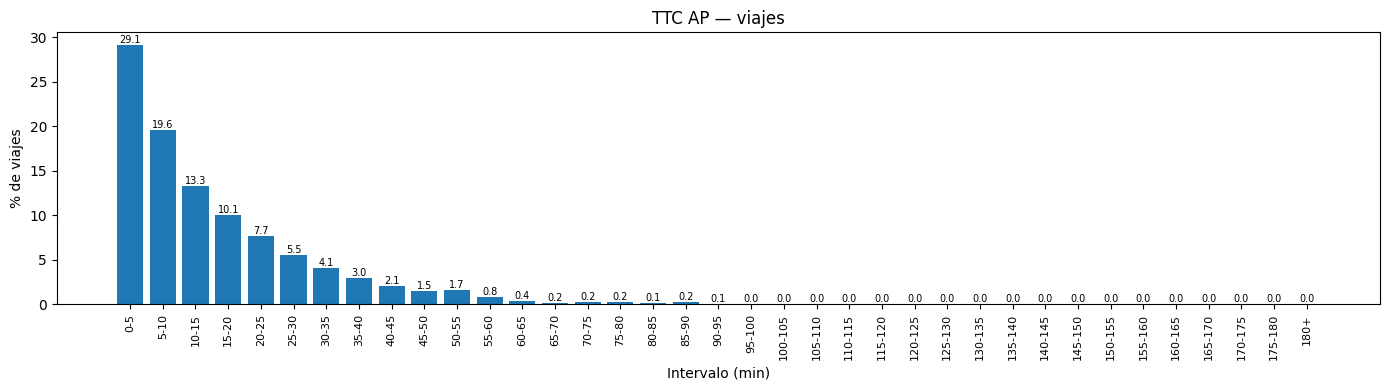

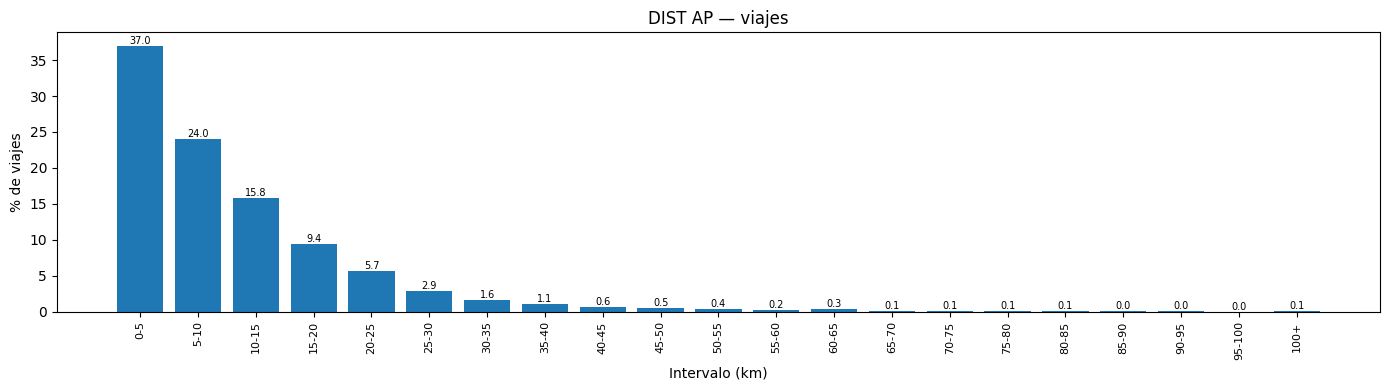

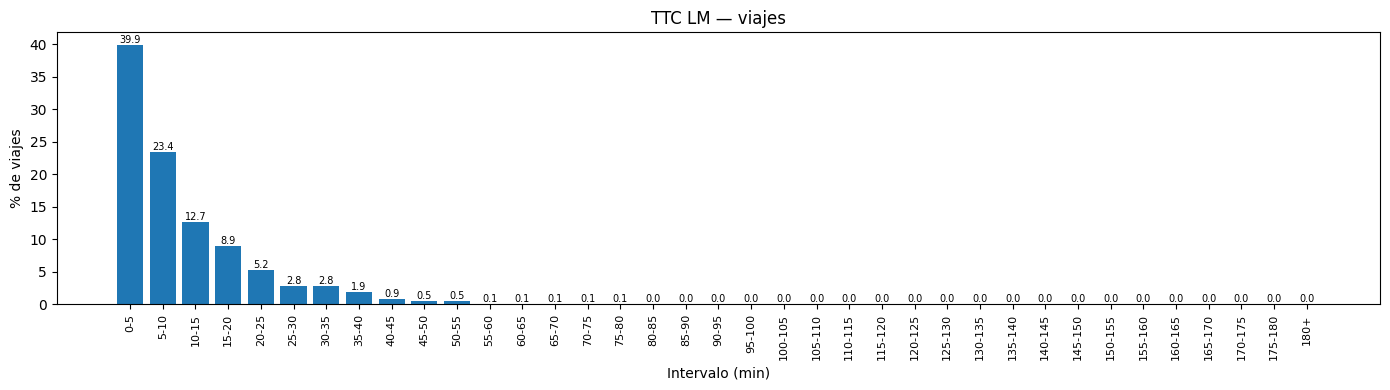

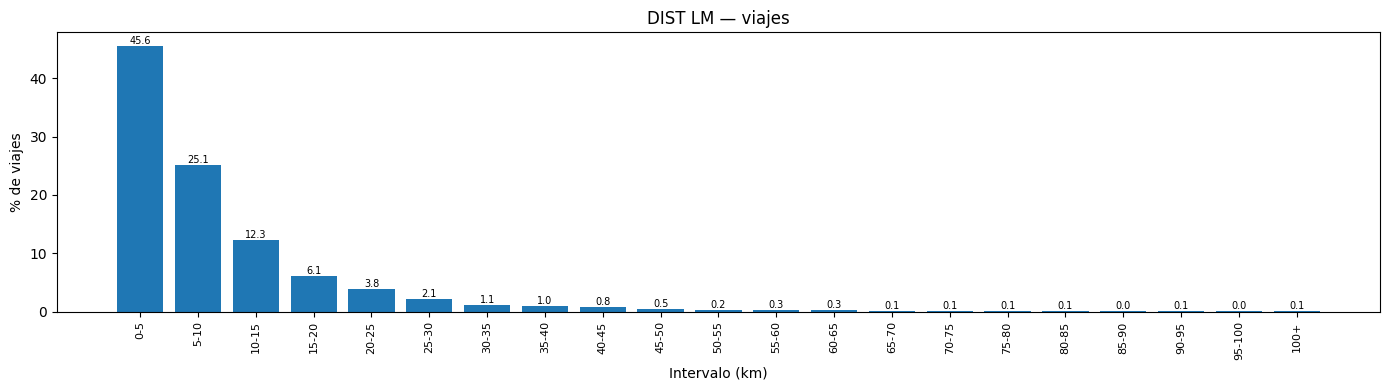

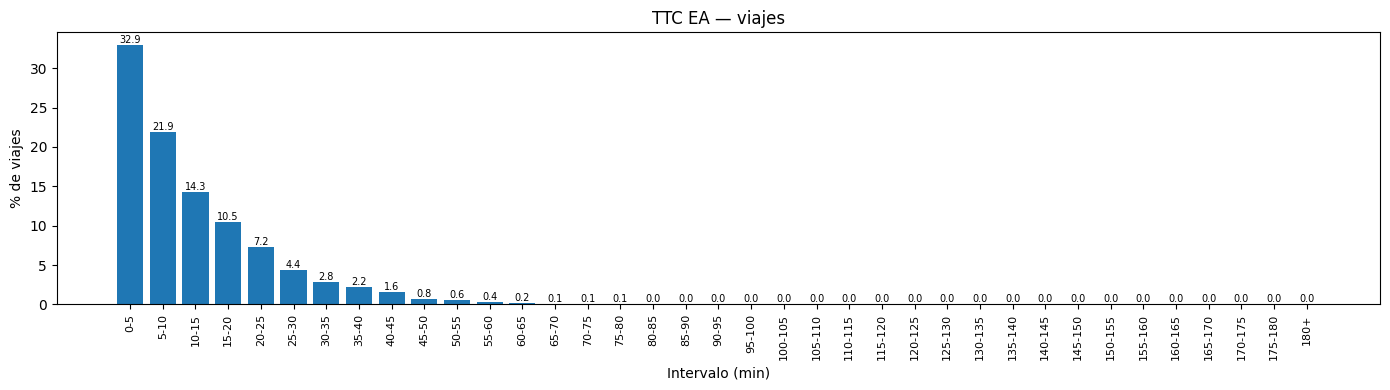

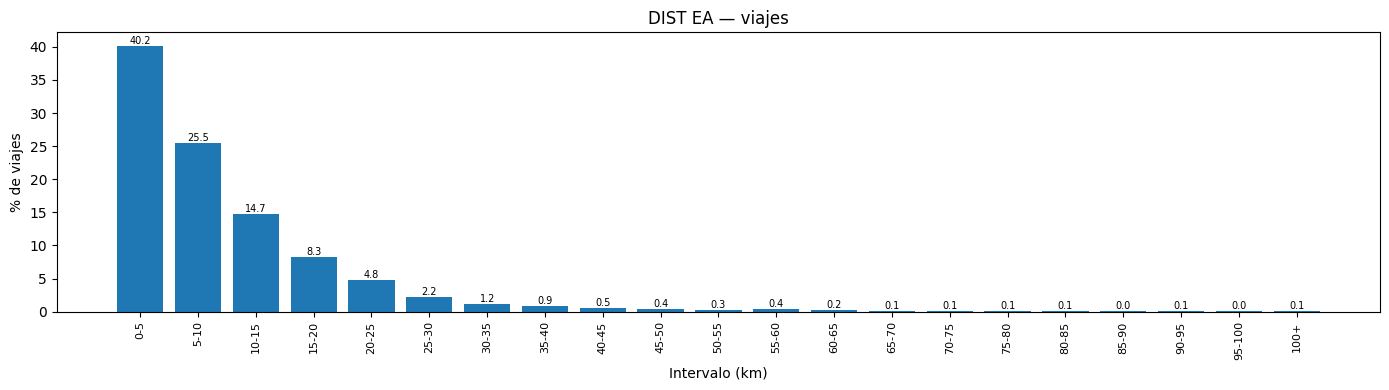

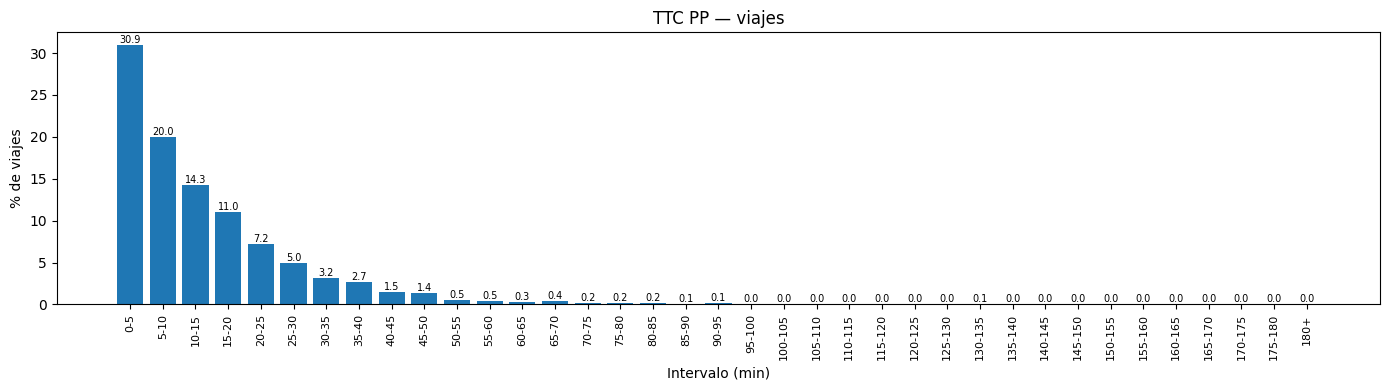

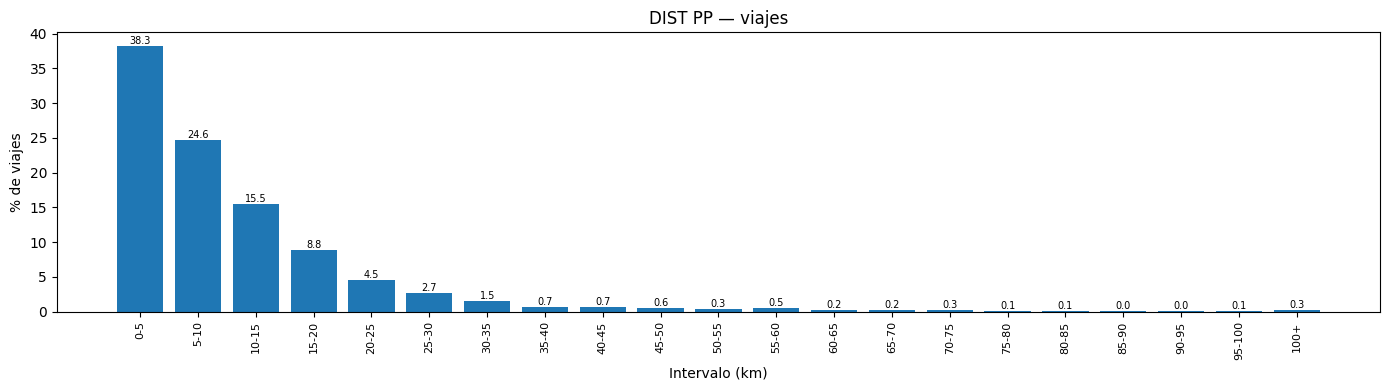

In [38]:
if HAY_ZONAS:
    hist_viajes = {}
    for p in PERIODOS:
        c = cruces[p]
        for tipo in ["TTC", "DIST"]:
            bins, labels, _ = config[tipo]
            intervalos = pd.cut(c[tipo], bins=bins, labels=labels, right=False)
            t = c.groupby(intervalos, observed=False)["Trips"].sum().rename("Viajes").to_frame()
            t["% viajes"] = (t["Viajes"] / t["Viajes"].sum() * 100).round(2)
            hist_viajes[f"{tipo}_{p}"] = t

    graficar(hist_viajes, "% viajes", "% de viajes", "viajes")


**Cruce con la demanda**
- Todas las zonas de la demanda se mapearon a la skim (0 pares sin mapeo) y ningún viaje cae en pares sin ruta: la zona desconectada (10008) no tiene demanda.
- Los viajes intrazonales (de una zona a sí misma) representan entre 4 y 6 % de los viajes de cada periodo y se excluyen de los histogramas porque su skim es 0.
- La distancia promedio por viaje (9.3–10.8 km) es menos de la mitad de la distancia promedio entre todos los pares (≈ 24 km): los viajes reales son mucho más cortos que una combinación de zonas al azar. Esto también confirma que el cruce entre demanda y skims es correcto.

**Tiempo (TTC)**
- El tiempo promedio por viaje es de 15.2 min en AP, 14.1 en PP, 12.3 en EA y 10.4 en LM.
- La mayoría de los viajes es corta: el intervalo más frecuente es de 0 a 5 min en los 4 periodos (29.1 % en AP y 39.9 % en LM).
- Los viajes de menos de 15 min son 62 % en AP, 65 % en PP, 69 % en EA y 76 % en LM.
- Los viajes de más de 30 min son ≈ 15 % en AP, 12 % en PP, 9 % en EA y 7 % en LM. AP es el periodo con viajes más largos y LM el de viajes más cortos.

**Distancia (DIST)**
- Entre 37 y 46 % de los viajes recorre menos de 5 km, y entre 61 y 71 % menos de 10 km.
- A diferencia de la distribución por pares, la distancia por viaje sí cambia entre periodos: LM tiene más viajes cortos (45.6 % de menos de 5 km) que AP (37.0 %). La red es la misma, así que la diferencia viene de los viajes que se hacen en cada periodo, no de las rutas.

**Pares vs viajes**
- Por pares, el intervalo más frecuente es de 25 a 30 min y de 15 a 20 km; por viajes, es de 0 a 5 min y de 0 a 5 km. Ver solo los pares sobrestima cuánto tarda y cuánto recorre un viaje típico.

parte de los viajes de 0 a 5 min puede incluir pares con tiempos casi nulos (ver reporte de velocidades imposibles), por lo que ese intervalo podría estar ligeramente sobrestimado

## Mapa de pares con más viajes
- **Grosor:** viajes (qué tan usado es el trayecto)
- **Color:** velocidad promedio DIST / TTC (rojo = lento, verde = rápido)

Las líneas gruesas y rojas son trayectos con mucha demanda y baja velocidad, que es donde más pesa la congestión. La escala de color es la misma en los 4 periodos para poder compararlos.

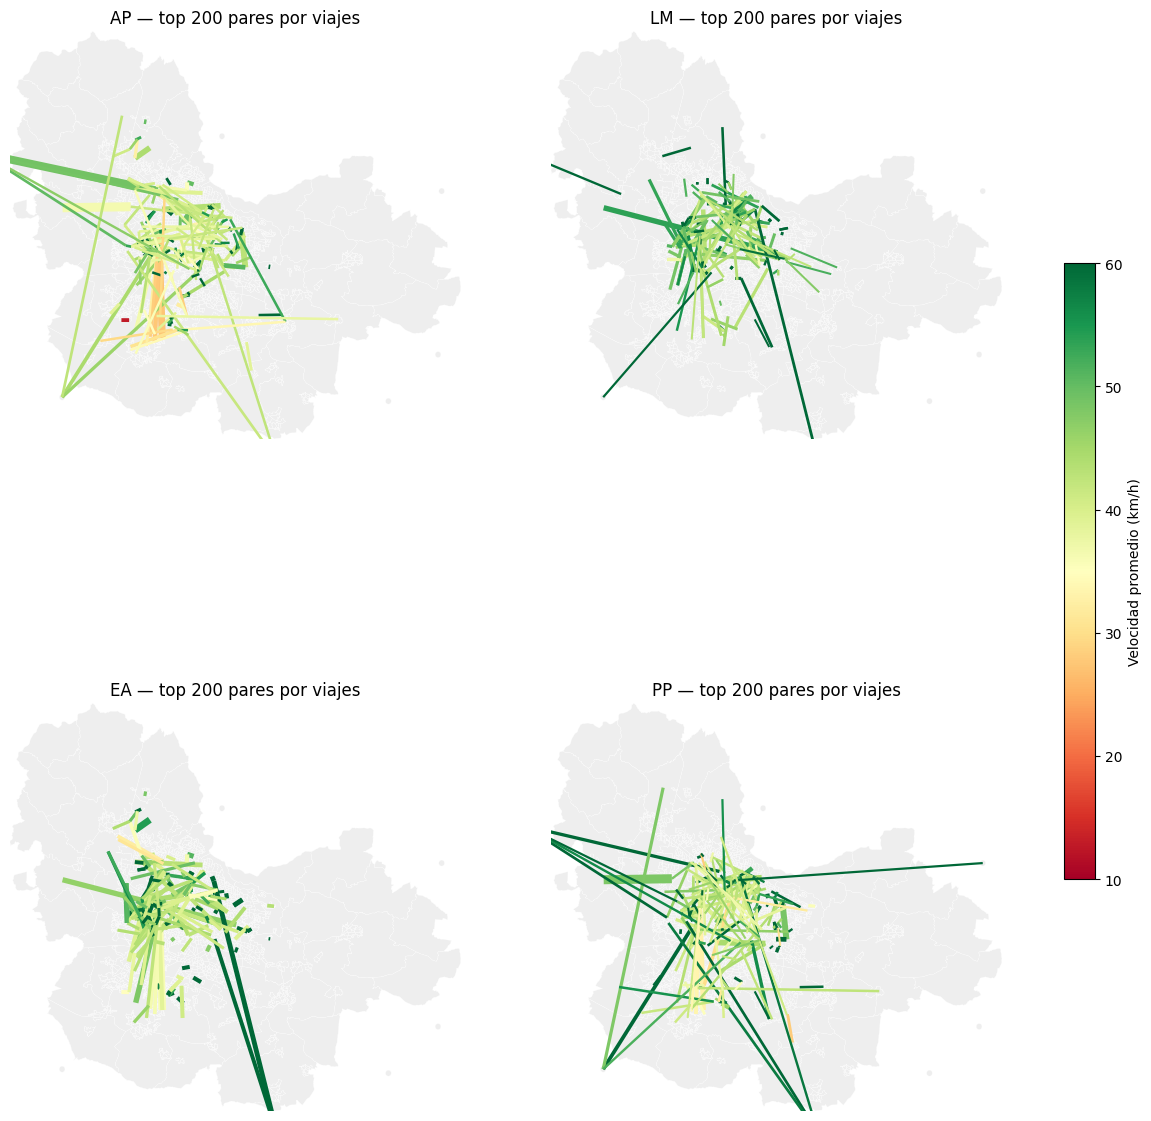

In [40]:
TOP = 200
VEL_MIN_COLOR, VEL_MAX_COLOR = 10, 60

mapa_pares = {}
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    c = cruces[p].nlargest(TOP, "Trips").copy()
    c["VEL_kmh"] = c["DIST"] / (c["TTC"] / 60)
    lineas = gpd.GeoDataFrame(
        c,
        geometry=[LineString([centros[o], centros[d]]) for o, d in zip(c["Origin_zona"], c["Destination_zona"])],
        crs=zonas_geo.crs,
    )
    mapa_pares[p] = lineas

    zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
    lineas.plot(ax=ax, column="VEL_kmh", cmap="RdYlGn", vmin=VEL_MIN_COLOR, vmax=VEL_MAX_COLOR,
                linewidth=(0.5 + 6 * c["Trips"] / c["Trips"].max()).values)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{p} — top {TOP} pares por viajes")
    ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(VEL_MIN_COLOR, VEL_MAX_COLOR), cmap="RdYlGn"),
             ax=axes, shrink=0.5, label="Velocidad promedio (km/h)")
plt.show()

Pares con más viajes y menor velocidad

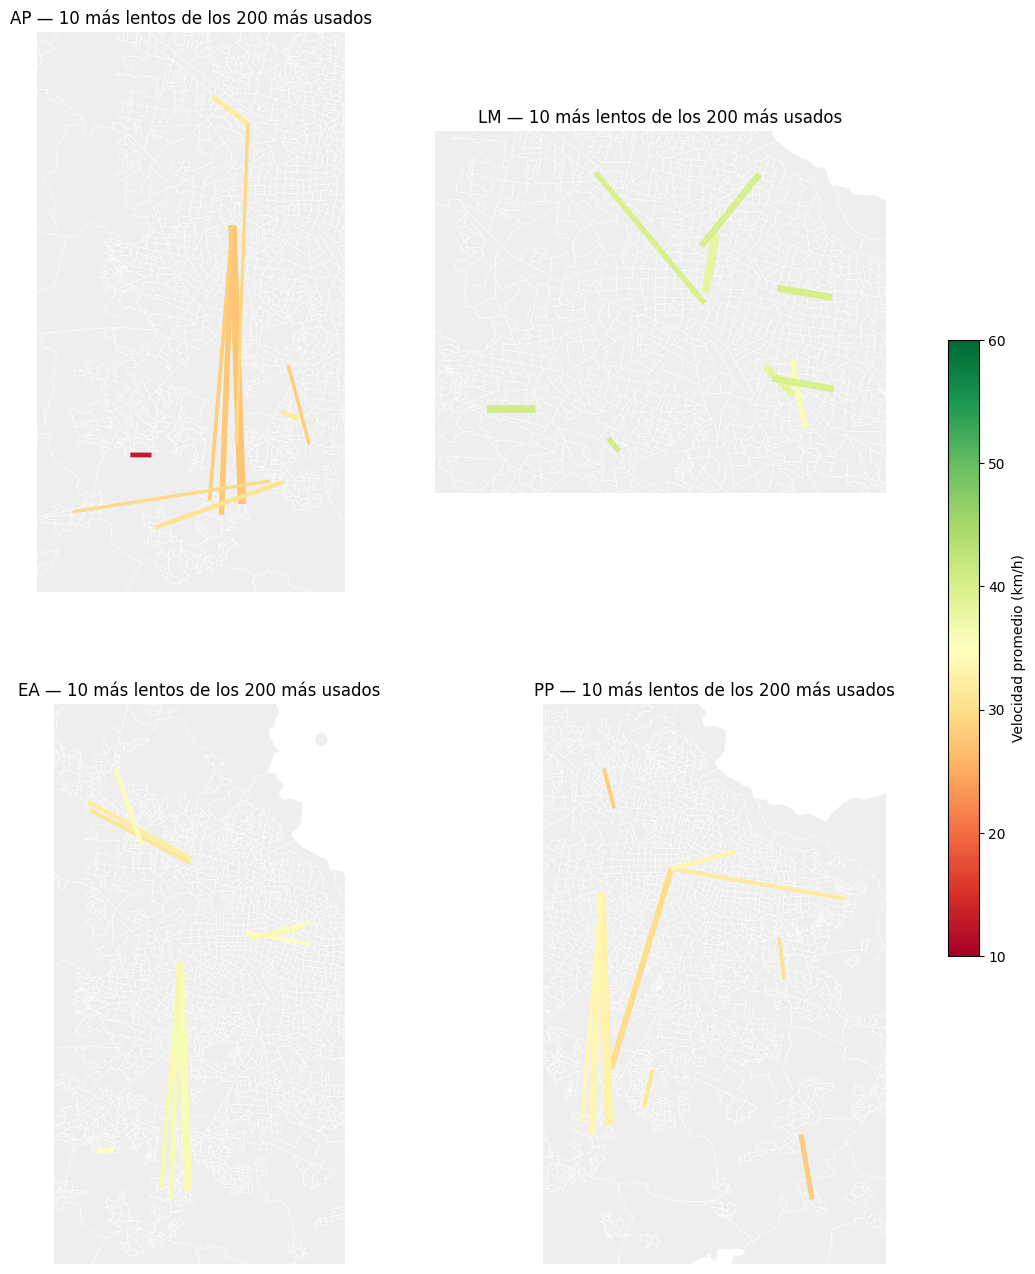

AP


,Origin_zona,Mun_origen,Destination_zona,Mun_destino,Trips,TTC,DIST,VEL_kmh
3759,5374,Tlajomulco de Zúñiga,5342,Tlajomulco de Zúñiga,305.9,8.8,1.9,12.8
3368,5238,Tlajomulco de Zúñiga,8015,Zapopan,622.1,54.2,24.7,27.4
3649,5336,Tlajomulco de Zúñiga,8015,Zapopan,380.2,53.2,24.5,27.6
3631,5331,Tlajomulco de Zúñiga,8015,Zapopan,207.4,49.2,23.1,28.2
3690,5356,Tlajomulco de Zúñiga,6053,San Pedro Tlaquepaque,177.9,14.1,6.6,28.2
3562,5316,Tlajomulco de Zúñiga,8011,Zapopan,177.9,53.7,26.2,29.3
3490,5285,Tlajomulco de Zúñiga,5155,Tlajomulco de Zúñiga,177.9,37.1,18.3,29.5
3458,5260,Tlajomulco de Zúñiga,5009,Tlajomulco de Zúñiga,266.9,25.4,12.9,30.6
6073,8055,Zapopan,8011,Zapopan,327.2,7.3,3.9,32.0
3543,5297,Tlajomulco de Zúñiga,5292,Tlajomulco de Zúñiga,317.7,5.8,3.1,32.1


LM


,Origin_zona,Mun_origen,Destination_zona,Mun_destino,Trips,TTC,DIST,VEL_kmh
2721,6164,San Pedro Tlaquepaque,193,Guadalajara,122.1,8.0,4.8,35.9
3708,8109,Zapopan,8013,Zapopan,183.2,6.1,3.8,37.1
379,111,Guadalajara,8,Guadalajara,207.8,5.8,3.7,38.1
2314,6017,San Pedro Tlaquepaque,6130,San Pedro Tlaquepaque,168.7,4.4,2.8,38.3
3719,8113,Zapopan,133,Guadalajara,122.1,16.7,11.1,39.8
2952,7065,Tonalá,6004,San Pedro Tlaquepaque,168.7,6.0,4.0,39.9
1197,434,Guadalajara,22,Guadalajara,155.0,9.6,6.4,40.1
1104,405,Guadalajara,99,Guadalajara,170.8,5.6,3.7,40.1
2754,6171,San Pedro Tlaquepaque,6153,San Pedro Tlaquepaque,111.8,9.7,6.5,40.3
3217,8013,Zapopan,8109,Zapopan,183.2,5.7,3.8,40.7


EA


,Origin_zona,Mun_origen,Destination_zona,Mun_destino,Trips,TTC,DIST,VEL_kmh
10168,8117,Zapopan,8442,Zapopan,102.3,21.6,11.2,31.0
9184,8029,Zapopan,8440,Zapopan,127.9,19.5,10.5,32.2
701,92,Guadalajara,121,Guadalajara,96.5,9.8,5.7,34.6
5811,5342,Tlajomulco de Zúñiga,5374,Tlajomulco de Zúñiga,141.1,3.2,1.9,34.9
10566,8167,Zapopan,8488,Zapopan,127.9,14.8,8.7,35.4
891,111,Guadalajara,63,Guadalajara,96.5,9.9,5.9,35.6
8757,8015,Zapopan,5238,Tlajomulco de Zúñiga,291.5,40.9,24.7,36.2
8764,8015,Zapopan,5336,Tlajomulco de Zúñiga,127.5,40.4,24.4,36.2
890,111,Guadalajara,62,Guadalajara,96.5,8.9,5.4,36.3
8761,8015,Zapopan,5331,Tlajomulco de Zúñiga,127.5,37.9,23.1,36.6


PP


,Origin_zona,Mun_origen,Destination_zona,Mun_destino,Trips,TTC,DIST,VEL_kmh
4029,8011,Zapopan,8073,Zapopan,168.8,9.5,4.4,28.0
1657,1028,Ixtlahuacán de los Membrillos,5362,Tlajomulco de Zúñiga,253.2,25.8,12.1,28.1
477,111,Guadalajara,5307,Tlajomulco de Zúñiga,322.5,38.6,19.2,29.8
3578,7043,Tonalá,6085,San Pedro Tlaquepaque,158.1,11.9,6.0,30.4
2615,5260,Tlajomulco de Zúñiga,5327,Tlajomulco de Zúñiga,215.0,7.2,3.8,31.4
500,111,Guadalajara,7901,Tonalá,191.9,34.6,18.3,31.7
4082,8015,Zapopan,5238,Tlajomulco de Zúñiga,501.1,46.1,25.3,32.8
4087,8015,Zapopan,5336,Tlajomulco de Zúñiga,375.8,45.1,25.0,33.2
430,111,Guadalajara,63,Guadalajara,221.2,10.7,5.9,33.4
4084,8015,Zapopan,5331,Tlajomulco de Zúñiga,167.0,42.3,23.7,33.5


In [43]:
lentos_usados = {}
fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    lineas = mapa_pares[p].nsmallest(10, "VEL_kmh").copy()
    lineas["Mun_origen"] = lineas["Origin_zona"].map(municipio)
    lineas["Mun_destino"] = lineas["Destination_zona"].map(municipio)
    lentos_usados[p] = lineas

    zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.3)
    lineas.plot(ax=ax, column="VEL_kmh", cmap="RdYlGn", vmin=VEL_MIN_COLOR, vmax=VEL_MAX_COLOR,
                linewidth=(1 + 5 * lineas["Trips"] / lineas["Trips"].max()).values)

    x0, y0, x1, y1 = lineas.total_bounds
    margen_x, margen_y = (x1 - x0) * 0.15, (y1 - y0) * 0.15
    ax.set_xlim(x0 - margen_x, x1 + margen_x)
    ax.set_ylim(y0 - margen_y, y1 + margen_y)
    ax.set_title(f"{p} — 10 más lentos de los {TOP} más usados")
    ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(VEL_MIN_COLOR, VEL_MAX_COLOR), cmap="RdYlGn"),
             ax=axes, shrink=0.5, label="Velocidad promedio (km/h)")
plt.show()

for p in PERIODOS:
    print(p)
    display(lentos_usados[p].drop(columns="geometry")[
        ["Origin_zona", "Mun_origen", "Destination_zona", "Mun_destino", "Trips", "TTC", "DIST", "VEL_kmh"]
    ].round(1))


- El trayecto más relevante es entre Tlajomulco (zonas 5238, 5331 y 5336) y Zapopan (zona 8015): unos 25 km con velocidades de 27 a 36 km/h. En AP va de Tlajomulco a Zapopan (hasta 54 min; el par de la zona 5238 a la 8015 tiene 622 viajes, el más alto de la tabla) y en EA y PP aparece en sentido contrario.
- En AP, 9 de los 10 pares más lentos salen de Tlajomulco. El más lento es un viaje corto dentro del mismo municipio, de la zona 5374 a la 5342: 1.9 km en 8.8 min, a 12.8 km/h.
- LM es el periodo más fluido: sus pares más lentos van de 36 a 41 km/h y son trayectos cortos dentro de Guadalajara, Zapopan y Tlaquepaque.
- En PP también aparecen viajes largos desde Guadalajara (zona 111) hacia Tlajomulco y Tonalá, a unos 30 km/h.

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados


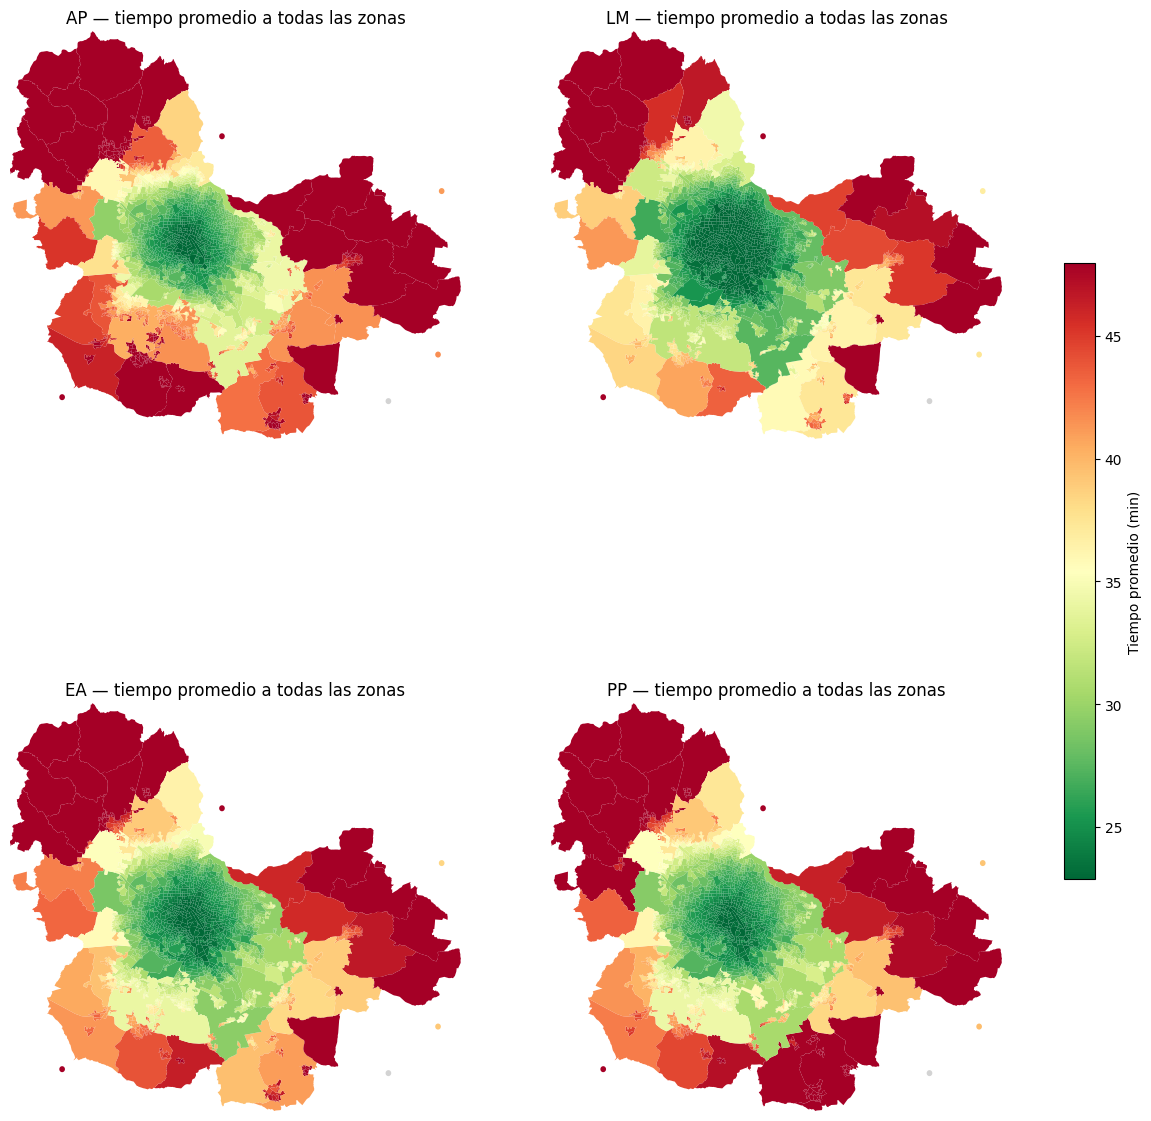

10 zonas mejor conectadas en AP


,AP,LM,EA,PP,Municipio
Zona_visum,,,,,
183,21.8,19.6,21.7,22.4,Guadalajara
213,21.9,19.6,21.5,22.1,Guadalajara
210,22.2,20.0,22.0,22.7,Guadalajara
182,22.3,20.2,22.3,23.1,Guadalajara
154,22.3,20.3,22.4,23.3,Guadalajara
199,22.3,20.2,22.4,23.2,Guadalajara
155,22.4,20.3,22.5,23.3,Guadalajara
258,22.4,19.9,21.7,22.0,Guadalajara
179,22.4,20.4,22.6,23.4,Guadalajara


10 zonas peor conectadas en AP


,AP,LM,EA,PP,Municipio
Zona_visum,,,,,
8900,97.9,88.4,91.9,91.4,Zapopan
8904,81.6,72.1,75.6,75.0,Zapopan
9908,72.5,68.4,69.8,70.7,Zapotlanejo
10002,71.2,57.6,61.5,60.4,Acceso_Colotlan
8901,70.3,56.7,60.6,59.5,Zapopan
10006,70.1,63.8,68.0,88.7,Acceso_Lopez_Mateos
8903,69.6,65.0,68.1,71.1,Zapopan
8518,68.3,52.3,56.3,55.2,Zapopan
8517,68.0,52.0,56.0,54.8,Zapopan


In [44]:
accesibilidad = {}
for p in PERIODOS:
    df = skims_long[f"TTC_{p}"]
    prom = df[df["valido"]].groupby("Origin")["TTC"].mean()
    prom.index = [zonas[int(fila)] for fila in prom.index]
    accesibilidad[p] = prom

tabla_acc = pd.DataFrame(accesibilidad)
tabla_acc.index.name = "Zona_visum"
tabla_acc["Municipio"] = tabla_acc.index.map(municipio)
tabla_acc.round(2).to_csv(os.path.join(RESULTADOS, "accesibilidad_ttc.csv"))
print("Guardado en", RESULTADOS)

todos = pd.concat(accesibilidad.values())
vmin, vmax = todos.quantile(0.05), todos.quantile(0.95)

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    zonas_geo["TTC_prom"] = zonas_geo["id_visum"].map(accesibilidad[p])
    zonas_geo.plot(ax=ax, column="TTC_prom", cmap="RdYlGn_r", vmin=vmin, vmax=vmax,
                   missing_kwds={"color": "lightgrey"})
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{p} — tiempo promedio a todas las zonas")
    ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(vmin, vmax), cmap="RdYlGn_r"),
             ax=axes, shrink=0.5, label="Tiempo promedio (min)")
plt.show()

print("10 zonas mejor conectadas en AP")
display(tabla_acc.sort_values("AP").head(10).round(1))
print("10 zonas peor conectadas en AP")
display(tabla_acc.sort_values("AP", ascending=False).head(10).round(1))

### Accesibilidad por zona

- Las zonas mejor conectadas están en el centro de Guadalajara: desde ahí, el tiempo promedio hacia el resto de la ciudad es de unos 22 min en AP y 20 min en LM.
- Las peor conectadas son zonas rurales de Zapopan (serie 8900), una zona rural de Zapotlanejo (9908) y los accesos carreteros, con promedios de 67 a 98 min en AP. Una zona periférica tarda de 3 a 4 veces más en llegar al resto de la ciudad que una zona del centro.
- En todas las zonas, LM es el periodo con tiempos más bajos y AP el de tiempos más altos, lo que coincide con la congestión.
- El acceso de López Mateos (10006) es la excepción: su tiempo promedio sube de 70 min en AP a 89 min en PP, por lo que es el único acceso que empeora tanto en la tarde. Vale la pena revisarlo.
- Las zonas mejor y peor conectadas son las mismas en los 4 periodos.

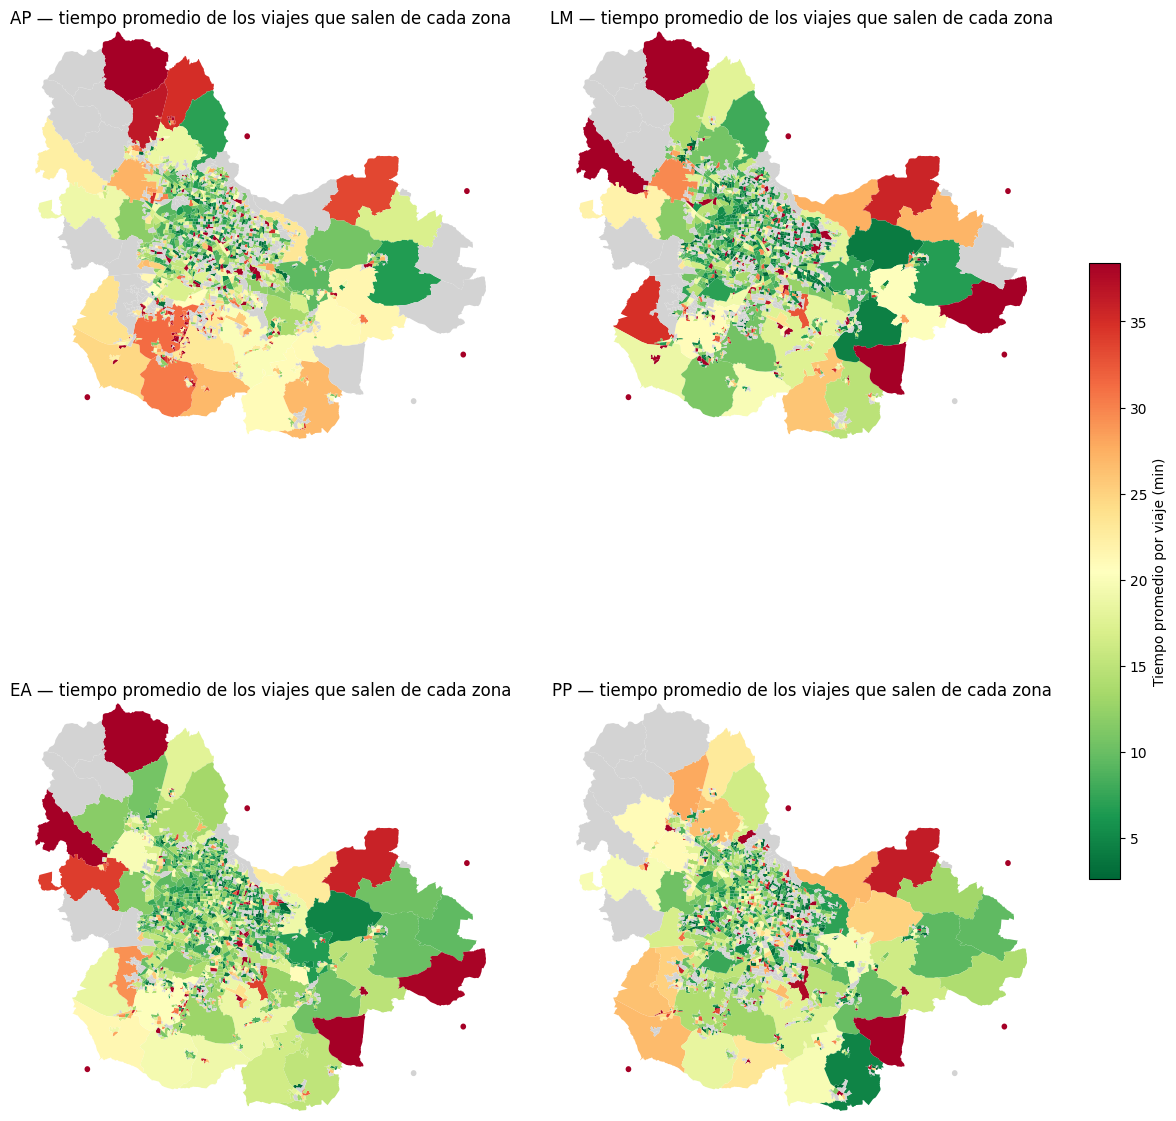

AP: 10 zonas con viajes más lentos (mínimo 100 viajes)


,TTC prom. por viaje (min),Viajes,Municipio,Periodo
Zona_visum,,,,
10006,72.1,251.3,Acceso_Lopez_Mateos,AP
5359,61.9,103.7,Tlajomulco de Zúñiga,AP
8521,59.7,260.3,Zapopan,AP
5286,54.8,241.9,Tlajomulco de Zúñiga,AP
5316,53.5,266.9,Tlajomulco de Zúñiga,AP
5336,53.0,414.7,Tlajomulco de Zúñiga,AP
5332,52.3,207.4,Tlajomulco de Zúñiga,AP
5334,51.7,172.8,Tlajomulco de Zúñiga,AP
5307,50.2,177.9,Tlajomulco de Zúñiga,AP


LM: 10 zonas con viajes más lentos (mínimo 100 viajes)


,TTC prom. por viaje (min),Viajes,Municipio,Periodo
Zona_visum,,,,
10006,63.8,334.3,Acceso_Lopez_Mateos,LM
7045,44.0,345.7,Tonalá,LM
10001,43.7,631.1,Acceso_Vallarta,LM
10004,41.3,382.6,Acceso_Zapotlanejo_Cuota,LM
10003,41.0,195.6,Acceso_Saltillo,LM
10005,40.7,615.5,Acceso_Chapala,LM
5375,37.4,142.7,Tlajomulco de Zúñiga,LM
5238,35.0,129.0,Tlajomulco de Zúñiga,LM
13,30.7,310.1,Guadalajara,LM


EA: 10 zonas con viajes más lentos (mínimo 100 viajes)


,TTC prom. por viaje (min),Viajes,Municipio,Periodo
Zona_visum,,,,
10006,66.8,538.7,Acceso_Lopez_Mateos,EA
9043,57.3,178.2,Zapotlanejo,EA
10005,43.4,1249.8,Acceso_Chapala,EA
10004,42.4,488.7,Acceso_Zapotlanejo_Cuota,EA
10001,42.2,1007.9,Acceso_Vallarta,EA
5286,40.7,145.7,Tlajomulco de Zúñiga,EA
10003,40.1,100.5,Acceso_Saltillo,EA
5238,34.7,205.6,Tlajomulco de Zúñiga,EA
8911,34.0,490.5,Zapopan,EA


PP: 10 zonas con viajes más lentos (mínimo 100 viajes)


,TTC prom. por viaje (min),Viajes,Municipio,Periodo
Zona_visum,,,,
10006,91.9,1858.8,Acceso_Lopez_Mateos,PP
9043,62.8,288.7,Zapotlanejo,PP
10005,60.6,2649.6,Acceso_Chapala,PP
8317,55.1,237.2,Zapopan,PP
5084,48.7,110.6,Tlajomulco de Zúñiga,PP
5331,47.3,208.8,Tlajomulco de Zúñiga,PP
8381,46.4,398.9,Zapopan,PP
5047,44.7,237.2,Tlajomulco de Zúñiga,PP
10003,41.7,235.0,Acceso_Saltillo,PP


Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados


In [47]:
MIN_VIAJES = 100   # para las tablas: solo zonas con al menos 100 viajes de salida

tiempo_viajes = {}
viajes_origen = {}
for p in PERIODOS:
    c = cruces[p].copy()
    c = c[c["DIST"] / (c["TTC"] / 60) <= VEL_MAX]      # quita pares con velocidad imposible
    c["TTC_x_Trips"] = c["TTC"] * c["Trips"]
    g = c.groupby("Origin_zona")[["TTC_x_Trips", "Trips"]].sum()
    tiempo_viajes[p] = g["TTC_x_Trips"] / g["Trips"]
    viajes_origen[p] = g["Trips"]

todos = pd.concat(tiempo_viajes.values())
vmin, vmax = todos.quantile(0.05), todos.quantile(0.95)

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    zonas_geo["TTC_viaje"] = zonas_geo["id_visum"].map(tiempo_viajes[p])
    zonas_geo.plot(ax=ax, column="TTC_viaje", cmap="RdYlGn_r", vmin=vmin, vmax=vmax,
                   missing_kwds={"color": "lightgrey"})
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{p} — tiempo promedio de los viajes que salen de cada zona")
    ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(vmin, vmax), cmap="RdYlGn_r"),
             ax=axes, shrink=0.5, label="Tiempo promedio por viaje (min)")
plt.show()

tablas_tv = []
for p in PERIODOS:
    t = pd.DataFrame({"TTC prom. por viaje (min)": tiempo_viajes[p], "Viajes": viajes_origen[p]})
    t.index.name = "Zona_visum"
    t["Municipio"] = t.index.map(municipio)
    t["Periodo"] = p
    tablas_tv.append(t)

    con_viajes = t[t["Viajes"] >= MIN_VIAJES]
    print(f"{p}: 10 zonas con viajes más lentos (mínimo {MIN_VIAJES} viajes)")
    display(con_viajes.sort_values("TTC prom. por viaje (min)", ascending=False).head(10).round(1))

pd.concat(tablas_tv).round(2).to_csv(os.path.join(RESULTADOS, "tiempo_por_viaje_origen.csv"))
print("Guardado en", RESULTADOS)


Se excluyen los pares con velocidades de más de 120 km/h y solo se consideran zonas con al menos 100 viajes de salida.

- El acceso de López Mateos (zona 10006) es la zona con los viajes más lentos en los 4 periodos: 72 min en AP, 64 en LM, 67 en EA y 92 en PP. En PP además tiene muchos viajes (1,859), por lo que es el punto que más conviene revisar.
- Los demás accesos carreteros (Chapala, Vallarta, Saltillo y Zapotlanejo) también aparecen entre los más lentos en casi todos los periodos. En parte es esperado, porque sus viajes son largos al venir de fuera de la ciudad.
- En AP, después del acceso de López Mateos, casi todas las zonas más lentas son de Tlajomulco (50 a 62 min por viaje). Coincide con el trayecto lento de Tlajomulco hacia Zapopan visto en los pares más usados.
- En PP, el acceso de Chapala (zona 10005) tiene el mayor número de viajes de la lista (2,650) con un tiempo promedio de 61 min.
- La zona 9043 de Zapotlanejo aparece en EA y PP con 57 a 63 min por viaje.
- LM es el periodo con tiempos más bajos: fuera de los accesos, sus zonas más lentas están entre 30 y 44 min.

## Mapas por tipo de vehículo


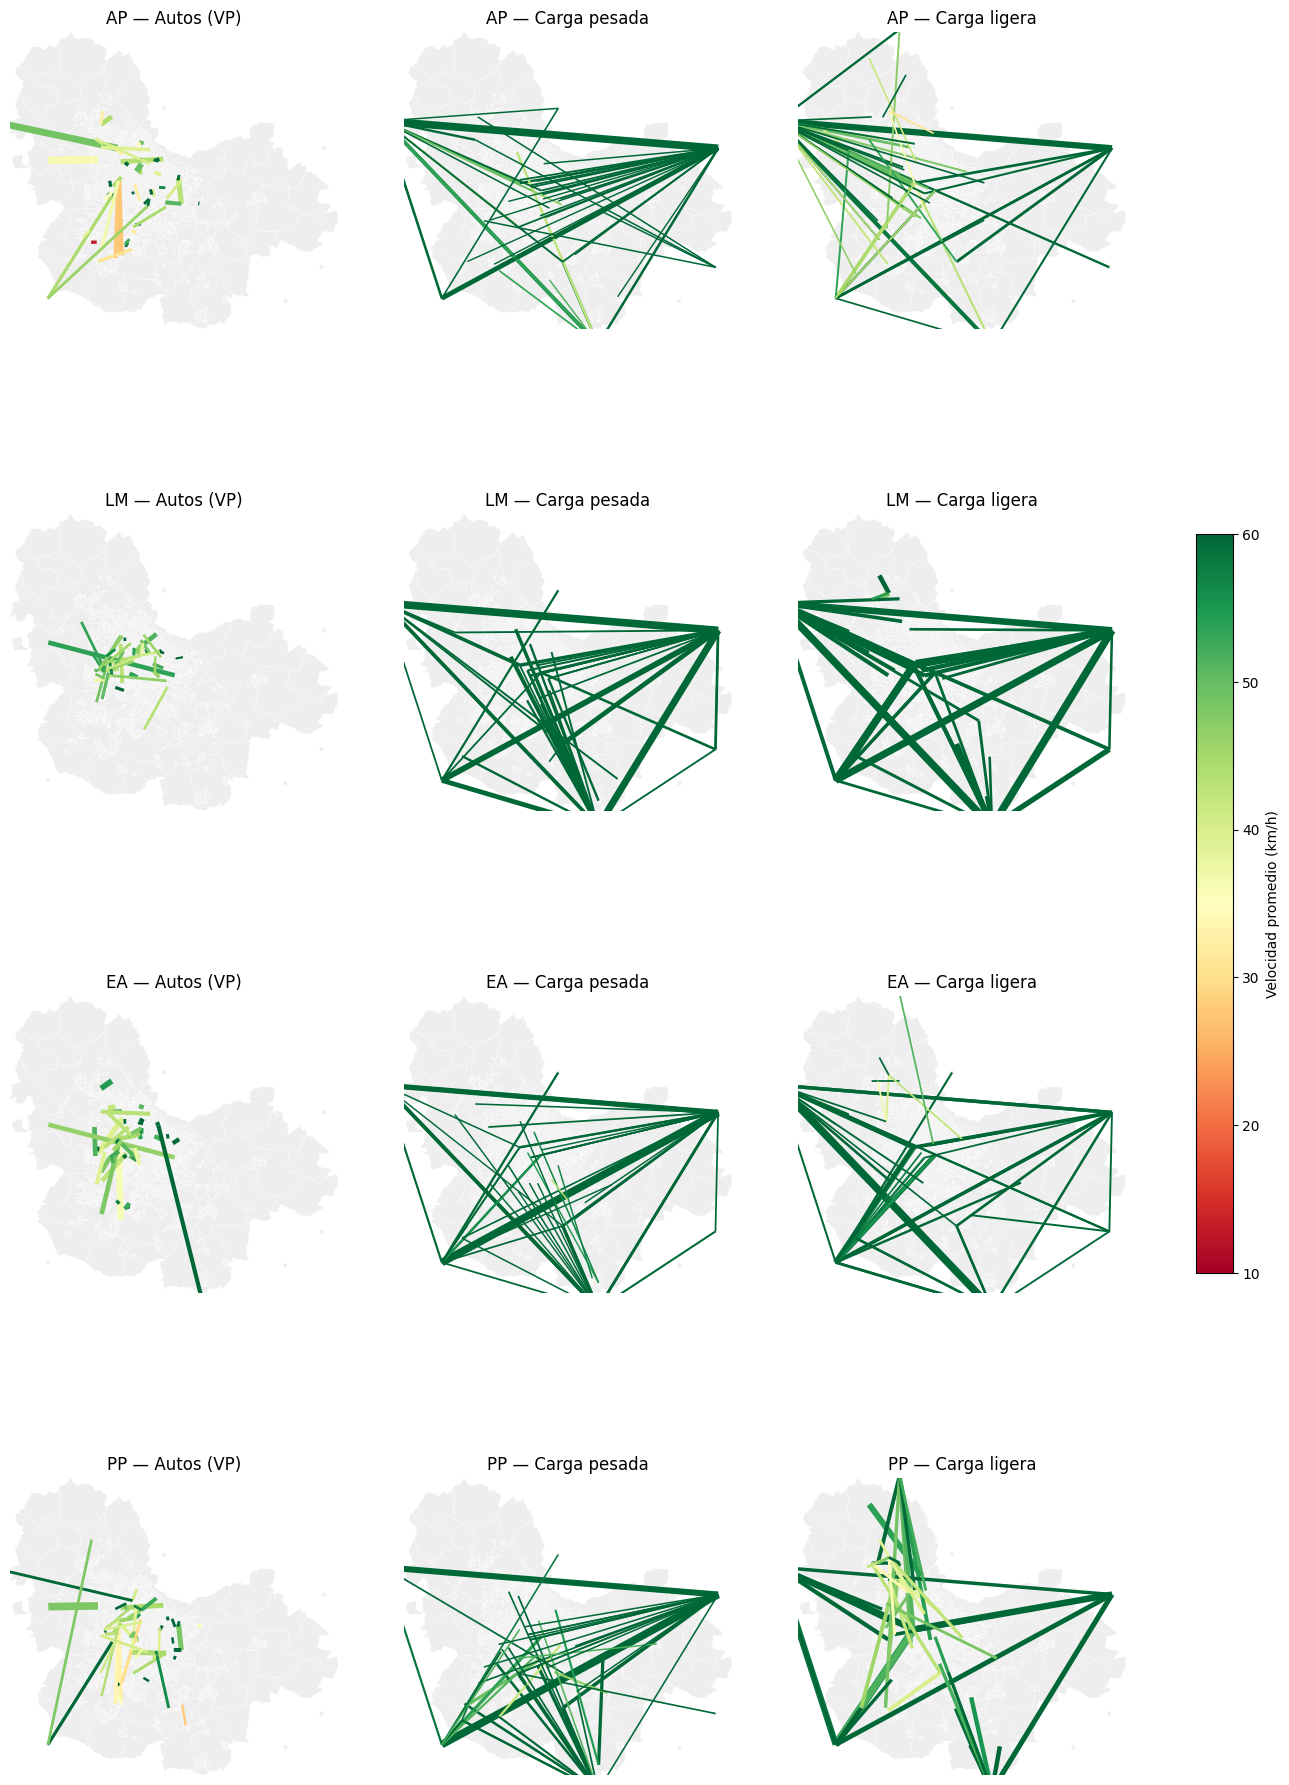

In [48]:
TOP_MODO = 50
NOMBRES_MODO = {"VP": "Autos (VP)", "HEAVY_FREIGHT": "Carga pesada", "LIGHT_FREIGHT": "Carga ligera"}

def lineas_de(c):
    geometria = [LineString([centros[o], centros[d]]) for o, d in zip(c["Origin_zona"], c["Destination_zona"])]
    return gpd.GeoDataFrame(c, geometry=geometria, crs=zonas_geo.crs)

tablas_modo = []
fig, axes = plt.subplots(4, 3, figsize=(18, 24))
for fila, p in enumerate(PERIODOS):
    skim_p = cruces[p][["Origin_zona", "Destination_zona", "TTC", "DIST"]]
    for col, modo in enumerate(MODOS):
        c = demanda_modo[(p, modo)].merge(skim_p, on=["Origin_zona", "Destination_zona"])
        c["VEL_kmh"] = c["DIST"] / (c["TTC"] / 60)
        c = c.nlargest(TOP_MODO, "Trips").copy()
        lineas = lineas_de(c)
        tablas_modo.append(c.assign(Periodo=p, Modo=NOMBRES_MODO[modo]))

        ax = axes[fila, col]
        zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
        lineas.plot(ax=ax, column="VEL_kmh", cmap="RdYlGn", vmin=VEL_MIN_COLOR, vmax=VEL_MAX_COLOR,
                    linewidth=(0.5 + 5 * c["Trips"] / c["Trips"].max()).values)
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.set_title(f"{p} — {NOMBRES_MODO[modo]}")
        ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(VEL_MIN_COLOR, VEL_MAX_COLOR), cmap="RdYlGn"),
             ax=axes, shrink=0.4, label="Velocidad promedio (km/h)")
plt.show()

tabla_modo = pd.concat(tablas_modo)[["Periodo", "Modo", "Origin_zona", "Destination_zona", "Trips", "TTC", "DIST", "VEL_kmh"]].round(2)

In [49]:
filas = []
for p in PERIODOS:
    skim_p = cruces[p][["Origin_zona", "Destination_zona", "TTC", "DIST"]]
    for modo in MODOS:
        c = demanda_modo[(p, modo)].merge(skim_p, on=["Origin_zona", "Destination_zona"])
        w = c["Trips"]
        filas.append({
            "Periodo": p,
            "Modo": NOMBRES_MODO[modo],
            "Viajes": round(w.sum(), 1),
            "TTC prom. por viaje (min)": round((c["TTC"] * w).sum() / w.sum(), 2),
            "DIST prom. por viaje (km)": round((c["DIST"] * w).sum() / w.sum(), 2),
        })

resumen_modo = pd.DataFrame(filas)
resumen_modo

,Periodo,Modo,Viajes,TTC prom. por viaje (min),DIST prom. por viaje (km)
0,AP,Autos (VP),345807.7,15.11,10.49
1,AP,Carga pesada,497.5,54.45,64.22
2,AP,Carga ligera,647.7,50.59,53.57
3,LM,Autos (VP),163123.5,9.98,8.55
4,LM,Carga pesada,1220.7,39.68,59.40
5,LM,Carga ligera,1517.2,35.74,49.78
6,EA,Autos (VP),285409.0,12.07,9.43
7,EA,Carga pesada,1165.4,43.88,60.45
8,EA,Carga ligera,1393.7,40.40,50.60
9,PP,Autos (VP),280622.0,13.91,10.55


- Los autos son casi la totalidad de los viajes (más del 99 % en todos los periodos). Sus viajes son cortos: de 8.5 a 10.5 km y de 10 a 15 min en promedio.
- Los viajes de carga son mucho más largos: la carga pesada recorre de 59 a 64 km por viaje y la carga ligera de 49 a 54 km, unas 6 veces más que un auto. Esto coincide con el mapa: la mayoría de sus trayectos entra o sale de la ciudad por los accesos carreteros.
- La carga también siente la congestión: un viaje de carga pesada tarda 54 min en AP y 40 min en LM, con distancias parecidas.
- Los viajes de carga se concentran en LM y EA (unos 1,200 de carga pesada y 1,400 a 1,500 de carga ligera) y bajan a la mitad en AP y PP, lo que sugiere que los camiones evitan las horas pico.
- La carga ligera tiene una distancia promedio de unos 50 km

In [50]:
imposibles = []
for p in PERIODOS:
    c = cruces[p].copy()
    c["VEL_kmh"] = c["DIST"] / (c["TTC"] / 60)
    r = c[c["VEL_kmh"] > VEL_MAX].copy()
    r["Periodo"] = p
    imposibles.append(r)

imposibles = pd.concat(imposibles)[["Periodo", "Origin_zona", "Destination_zona", "Trips", "TTC", "DIST", "VEL_kmh"]]

resumen_imp = imposibles.groupby("Periodo")["Trips"].agg(["count", "sum"]).loc[PERIODOS]
resumen_imp.columns = ["Pares con viajes", "Viajes afectados"]
print("Pares con velocidad mayor a", VEL_MAX, "km/h que sí tienen viajes")
display(resumen_imp.round(1))

print("10 con más viajes")
display(imposibles.sort_values("Trips", ascending=False).head(10).round(2))

Pares con velocidad mayor a 120 km/h que sí tienen viajes


,Pares con viajes,Viajes afectados
Periodo,,
AP,454,20357.7
LM,414,14203.7
EA,753,18169.8
PP,358,17248.4


10 con más viajes


,Periodo,Origin_zona,Destination_zona,Trips,TTC,DIST,VEL_kmh
2865,LM,7016,7017,612.57,0.37,0.88,143.66
2867,LM,7017,7016,532.31,0.14,0.75,322.46
7080,AP,8247,8021,490.82,0.25,0.68,167.10
3523,PP,7011,6029,474.41,1.03,2.24,129.90
3438,AP,5250,5251,444.87,0.30,0.84,166.84
4528,PP,8066,8065,355.81,0.43,0.85,120.17
812,AP,232,13,332.36,0.19,1.06,331.97
7124,AP,8255,8321,294.49,0.71,1.62,136.30
6022,AP,8041,8039,294.49,0.13,1.66,773.50
4499,AP,6157,6159,267.66,0.43,1.57,218.30


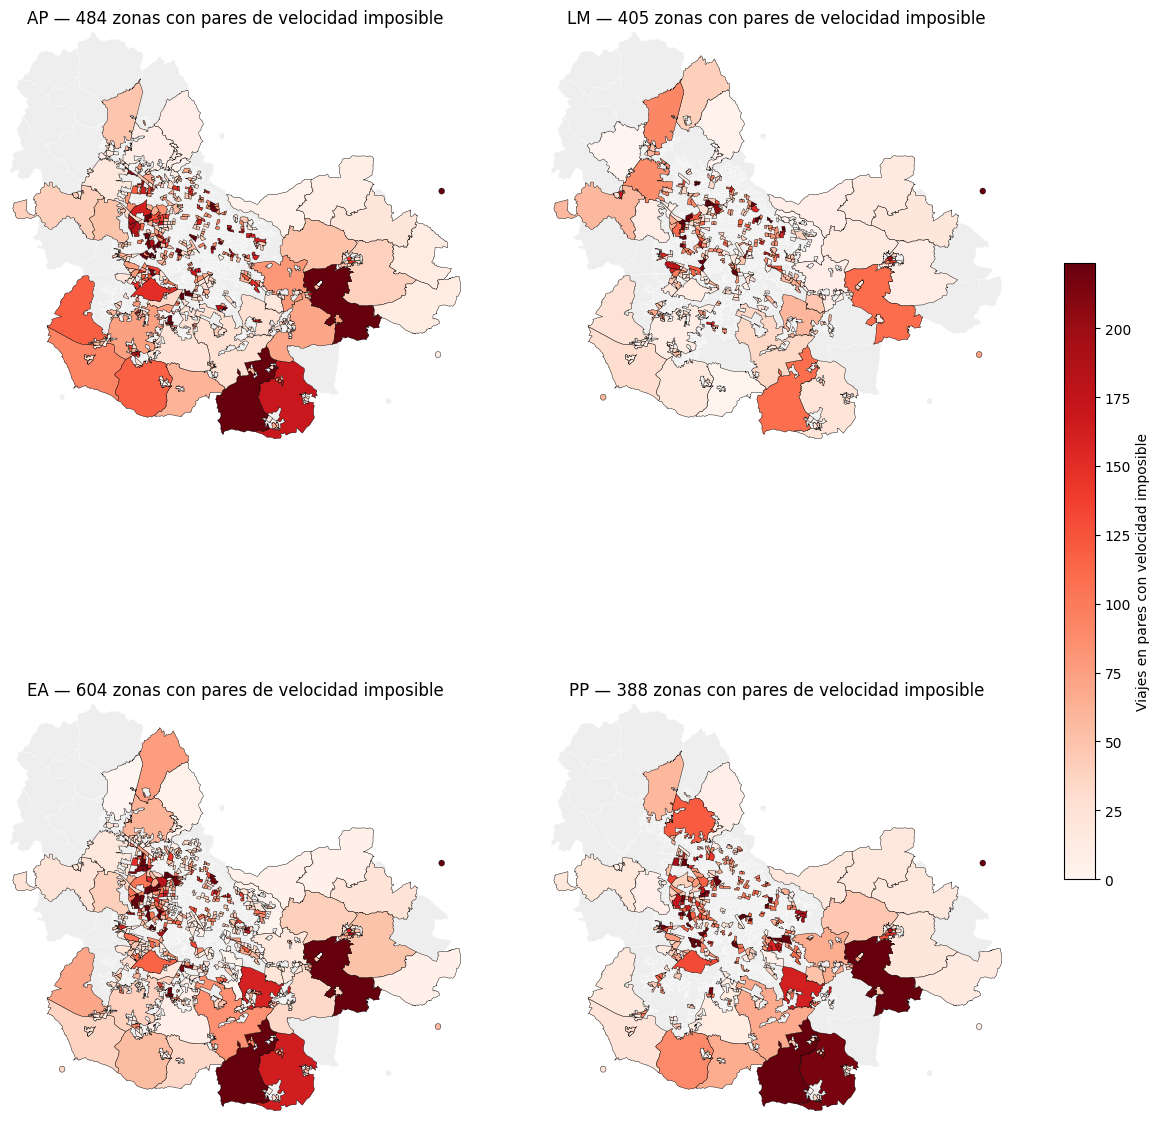

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados
10 zonas con más viajes afectados (suma de los 4 periodos)


,Viajes_afectados,Periodos,Municipio
Zona,,,
10004,1507.0,4,Acceso_Zapotlanejo_Cuota
5251,1449.5,4,Tlajomulco de Zúñiga
7016,1367.0,3,Tonalá
8038,1360.5,4,Zapopan
7017,1316.9,2,Tonalá
8247,1180.9,3,Zapopan
8041,1094.4,3,Zapopan
8001,1062.1,4,Zapopan
9906,1057.7,4,Zapotlanejo


In [51]:
extremos = pd.concat([
    imposibles[["Periodo", "Origin_zona", "Trips"]].rename(columns={"Origin_zona": "Zona"}),
    imposibles[["Periodo", "Destination_zona", "Trips"]].rename(columns={"Destination_zona": "Zona"}),
])
viajes_zona = extremos.groupby(["Periodo", "Zona"])["Trips"].sum()
vmax_err = viajes_zona.quantile(0.95)

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
for ax, p in zip(axes.flat, PERIODOS):
    v = viajes_zona.loc[p]
    zonas_geo["Viajes_err"] = zonas_geo["id_visum"].map(v)
    zonas_geo.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
    zonas_geo[zonas_geo["Viajes_err"].notna()].plot(ax=ax, column="Viajes_err", cmap="Reds",
                                                    vmin=0, vmax=vmax_err, edgecolor="black", linewidth=0.3)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_title(f"{p} — {len(v)} zonas con pares de velocidad imposible")
    ax.set_axis_off()

fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, vmax_err), cmap="Reds"),
             ax=axes, shrink=0.5, label="Viajes en pares con velocidad imposible")
plt.show()

total_zona = extremos.groupby("Zona").agg(Viajes_afectados=("Trips", "sum"), Periodos=("Periodo", "nunique"))
total_zona["Municipio"] = total_zona.index.map(municipio)
total_zona = total_zona.sort_values("Viajes_afectados", ascending=False)
total_zona.round(1).to_csv(os.path.join(RESULTADOS, "zonas_velocidad_imposible.csv"))
print("Guardado en", RESULTADOS)

print("10 zonas con más viajes afectados (suma de los 4 periodos)")
display(total_zona.head(10).round(1))


- Entre 358 y 753 pares con viajes tienen velocidades de más de 120 km/h, según el periodo. En total afectan de 14,204 a 20,358 viajes por periodo, entre 5.6 % y 8.0 % de los viajes (AP 5.6 %, LM 8.0 %, EA 6.0 %, PP 5.7 %).
- Son trayectos cortos entre zonas vecinas, de menos de 2.5 km, con tiempos de menos de un minuto. El caso con más viajes es entre las zonas 7016 y 7017 de Tonalá en LM: 613 y 532 viajes, en 0.37 y 0.14 min para menos de 1 km.
- Las zonas con más viajes afectados (suma de los 4 periodos) son el acceso de Zapotlanejo cuota (10004, 1,507 viajes), la zona 5251 de Tlajomulco (1,450), las zonas 7016 y 7017 de Tonalá (1,367 y 1,317) y varias zonas de Zapopan (8038, 8247, 8041 y 8001).
- Varias de estas zonas aparecen en los 4 periodos, lo que apunta a un problema fijo de la red cerca de ellas (por ejemplo, en sus conectores) y no a la congestión.
- Como estos viajes tienen tiempos casi nulos, bajan el tiempo promedio por viaje de la sección 9 y aumentan el intervalo de 0 a 5 min de los histogramas por viajes. Conviene revisar estas zonas en Visum.


## Exportar tablas resumen

In [54]:
desconectadas = sorted({zonas[int(f)] for f in todas_inalcanzables | todas_aisladas})

with pd.ExcelWriter(os.path.join(RESULTADOS, "resumen_skims.xlsx")) as xls:
    # Sección 5
    resumen_pares.to_excel(xls, sheet_name="pares", index=False)
    pd.DataFrame({"Zona_visum": desconectadas}).to_excel(xls, sheet_name="zonas_desconectadas", index=False)

    # Sección 6
    estadisticos.to_excel(xls, sheet_name="estadisticos")

    # Sección 7
    pares_umbral.to_excel(xls, sheet_name="umbrales", index=False)
    velocidades.to_excel(xls, sheet_name="velocidades", index=False)
    rangos_vel.to_excel(xls, sheet_name="rangos_vel")
    rangos_vel_pct.to_excel(xls, sheet_name="rangos_vel_pct")
    reporte.to_excel(xls, sheet_name="vel_imposible", index=False)
    lentos.to_excel(xls, sheet_name="pares_5_20_kmh", index=False)

    # Sección 8
    for nombre, t in hist_pares.items():
        t.to_excel(xls, sheet_name=f"pares_{nombre}")

    # Sección 9
    viajes_modo.to_excel(xls, sheet_name="demanda_modo", index=False)
    totales.to_excel(xls, sheet_name="totales_viajes")
    resumen_viajes.to_excel(xls, sheet_name="resumen_viajes", index=False)
    comparacion_vel.to_excel(xls, sheet_name="comparacion_vel", index=False)
    for nombre, t in hist_viajes.items():
        t.to_excel(xls, sheet_name=f"viajes_{nombre}")

    # Sección 10
    pd.concat([l.drop(columns="geometry").assign(Periodo=p) for p, l in mapa_pares.items()]) \
        .to_excel(xls, sheet_name="top200_pares", index=False)
    pd.concat([l.drop(columns="geometry").assign(Periodo=p) for p, l in lentos_usados.items()]) \
        .to_excel(xls, sheet_name="lentos_mas_usados", index=False)
    tabla_acc.to_excel(xls, sheet_name="accesibilidad")
    pd.concat(tablas_tv).to_excel(xls, sheet_name="tiempo_por_viaje_origen")
    tabla_modo.to_excel(xls, sheet_name="top_pares_modo", index=False)
    resumen_modo.to_excel(xls, sheet_name="resumen_modo", index=False)
    resumen_imp.to_excel(xls, sheet_name="imposibles_resumen")
    imposibles.to_excel(xls, sheet_name="imposibles_con_viajes", index=False)
    total_zona.to_excel(xls, sheet_name="zonas_imposibles")

print("Guardado en", RESULTADOS)

Guardado en C:\proyectos\red-vial-guadalajara\skim_matrices\resultados


## Conclusiones

**Calidad de las skims**
- Las 8 skims están bien formadas (2,105 zonas) y la velocidad mediana (41 a 47 km/h) confirma que TTC está en minutos y DIST en km.
- La zona 10008 (Acceso Ocotlán) no tiene ruta hacia ni desde ninguna otra zona. Probablemente le falta su conector.
- Entre 6,700 y 7,700 pares por periodo tienen velocidades de más de 120 km/h, con tiempos de menos de un segundo en distancias de 0.5 a 1.5 km. Los que tienen viajes afectan entre 5.6 % y 8.0 % de los viajes de cada periodo y se concentran en zonas como el acceso de Zapotlanejo cuota (10004), la 5251 de Tlajomulco, las 7016 y 7017 de Tonalá y varias de Zapopan. Revisarlas en Visum.

**Tiempo y distancia**
- El tiempo cambia por periodo y la distancia no: AP es el periodo más lento y LM el más rápido, mientras que las distancias son prácticamente iguales en los 4 periodos. Las rutas son similares; lo que cambia es la velocidad por la congestión.
- Por viajes (cruce con la demanda), un viaje típico dura de 10 a 16 min y recorre de 9 a 11 km, a velocidades promedio de 41 km/h en AP a 52 km/h en LM, aun quitando los pares de velocidad imposible. Son velocidades altas para viajes urbanos. Los viajes reales son mucho más cortos que el promedio entre todos los pares (unos 24 km).

**Trayectos y zonas lentas**
- El trayecto con más viajes y más lento es entre zonas de Tlajomulco (5238, 5331 y 5336) y la zona 8015 de Zapopan: unos 25 km a 27 a 36 km/h, hacia Zapopan en AP y de regreso en EA y PP.
- Los pares de 5 a 20 km/h solo aparecen en AP y PP y se concentran en pocas zonas: el acceso 10009 en AP y punts en Tlajomulco y Tonalá en PP.
- El acceso de López Mateos (10006) tiene los viajes más lentos en los 4 periodos, hasta 92 min en PP.

**Carga**
- La carga representa menos del 1 % de los viajes. Sus viajes son unas 6 veces más largos que los de auto (de 50 a 64 km) y la mayoría entra o sale de la ciudad por los accesos carreteros. Se concentra en LM y EA.